# Universidad Peruana de Ciencias Aplicadas (UPC)
# Predicción del Valor Comercial y Tasación Inmobiliaria en Lima Metropolitana
### Trabajo Final (TF1) - Curso: Data Mining Tools (CC209)
**Docente:** Carlos Fernando Montoya Cubas  
**Solución Metodológica:** Ensamble Ponderado Calibrado con Optuna sobre Valor Unitario (US$/m²), Clustering Espacial de Submercados ($K$-Means con Validación de Codo y Silueta), Ingeniería de Habitabilidad sin Data Leakage y Explicabilidad TreeSHAP.

---
### Estructura de Secciones:
* **Sección 01:** Problema de negocio, dataset de origen, cobertura geográfica y limitaciones.
* **Sección 02:** Análisis exploratorio de datos (EDA) y fundamento de la predicción en valor unitario (US$/m²).
* **Sección 03:** Limpieza auditada, delimitación contemporánea (2022–2026) y partición temporal triple out-of-time.
* **Sección 04:** Técnica no supervisada: Justificación sistemática de $k=4$ (Codo y Silueta) y caracterización de macro-submercados.
* **Sección 05:** Ingeniería de características: Ratios de habitabilidad, tipología inmobiliaria y garantía anti-leakage.
* **Sección 06:** Pipeline de preprocesamiento Scikit-Learn (`ColumnTransformer`).
* **Sección 07:** Enfoque de modelado sobre US$/m², optimización bayesiana con Optuna y calibración del ensamble.
* **Sección 08:** Evaluación en Test Ciego (2024–2026, $N=25,042$) y tabla comparativa oficial TP1 $\rightarrow$ TF1.
* **Sección 09:** Interpretabilidad global y local con TreeSHAP.
* **Sección 10:** Diagnóstico sistemático de errores residuales y análisis de casos extremos.
* **Sección 11:** Arquitectura de la solución, aplicación interactiva en Streamlit y conclusiones.

# Predicción del valor comercial de departamentos

# 01. Problema y dataset de origen

**Responsable:** Gabriel Reyna · **Secciones de la guía:** 4.2.1, 4.2.2

Este notebook define el problema y documenta el dataset a partir de los datos crudos del BCRP: su contexto, necesidad, unidad de análisis, pregunta principal, cobertura geográfica y temporal, diccionario de variables, condiciones de uso y limitaciones conocidas.

> Antes de subir cambios: *Kernel > Restart & Run All*.


In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor

from src import config
from src import limpieza
from src.baseline import ReglaMercadoM2
from src.datos import cargar_datos
from src.metricas import evaluar, errores_porcentuales, tabla_comparativa

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110

df = cargar_datos()
df["precio_m2"] = df["precio_usd"] / df["superficie_m2"]
print(f"{df.shape[0]:,} filas, {df.shape[1] - 1} columnas originales")

Matplotlib created a temporary cache directory at /tmp/matplotlib-5kzvp5wx because the default path (/home/Yair/.config/matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


119,980 filas, 16 columnas originales


## 1. Definición del problema (4.2.1)

**Qué queremos lograr.** Estimar el precio de oferta en dólares de un departamento en Lima Metropolitana a partir de su ubicación y sus características, y comprobar si esa estimación es mejor que la regla que ya usa el mercado.

**Contexto.** En Lima, los departamentos se anuncian y negocian casi siempre en dólares. Quien vende fija el precio mirando anuncios parecidos del mismo distrito, y quien compra no tiene una referencia objetiva para saber si un precio es razonable. Además, el precio por m² cambió mucho en el tiempo (ver la tabla de abajo), así que una referencia de hace pocos años ya no sirve sin ajustes.

**Necesidad.** La referencia más usada es simple: "precio por m² típico del distrito × metraje". Esa regla ignora baños, cocheras, antigüedad y el momento del mercado. Un modelo que considere todo eso puede dar una referencia más precisa a compradores, vendedores y corredores.

**Unidad de análisis.** Un anuncio de venta de un departamento en un trimestre. Cada fila es un anuncio, no una venta concretada.

**Pregunta principal.** ¿Con qué error se puede estimar el precio de oferta en dólares de un departamento en Lima Metropolitana, usando su distrito, metraje, dormitorios, baños, cocheras, antigüedad y trimestre de publicación, para anuncios de los trimestres más recientes?

**Tipo de problema.** Regresión supervisada. La evaluación se hace sobre anuncios posteriores a los del entrenamiento, porque así se usaría el modelo en la vida real.

**Utilidad esperada.** Un comprador puede saber si un anuncio está caro o barato frente a otros parecidos; un vendedor, fijar un precio de lista razonable; un corredor, detectar precios mal ingresados.

**Criterios de utilidad.** El modelo será útil si:
1. Reduce el error frente a la regla de mercado (sección 6), no solo frente a un modelo trivial.
2. Baja el error porcentual mediano a 10% o menos (umbral propuesto, a validar en equipo).
3. Ningún distrito con volumen suficiente queda con error mediano mayor a 20%.

**Lo que el proyecto no responde.** No estima el precio final de venta, porque los datos son precios de anuncio. Tampoco explica causas: si los departamentos con cochera cuestan más, no podemos afirmar que la cochera "causa" el mayor precio.

In [2]:
# Evidencia del contexto: mediana de US$/m² en años clave
mediana_m2_anio = df.groupby("anio")["precio_m2"].median()
anios_clave = [1998, 2007, 2014, 2022, 2025]
print(mediana_m2_anio.loc[anios_clave].round(0).astype(int).to_string())
print(f"\n2007 -> 2014: el precio por m² se multiplicó por "
      f"{mediana_m2_anio[2014] / mediana_m2_anio[2007]:.2f}")

anio
1998     636
2007     558
2014    1592
2022    1606
2025    1804

2007 -> 2014: el precio por m² se multiplicó por 2.86


**Interpretación.** Entre 2007 y 2014 la mediana del precio por m² casi se triplicó; después se mantuvo estable hasta 2022 y volvió a subir. Esto confirma que el momento del anuncio es tan importante como sus características, y justifica evaluar el modelo con anuncios posteriores a los de entrenamiento. La evolución detallada se analiza en el EDA (notebook 02).

## 2. Dataset y procedencia

| Campo | Valor |
| --- | --- |
| Fuente | Banco Central de Reserva del Perú (BCRP), base desagregada de precios de venta de departamentos |
| Origen del dato | 1998–2007: anuncios en periódicos impresos. Desde 2008: portales web especializados (Urbania) ([BCRP, DT 006-2018](https://www.bcrp.gob.pe/docs/Publicaciones/Documentos-de-Trabajo/2018/documento-de-trabajo-006-2018.pdf); [BCRP, Nota de Estudios 65-2025](https://www.bcrp.gob.pe/docs/Publicaciones/Notas-Estudios/2025/nota-de-estudios-65-2025.pdf)) |
| Tipo de precio | Precio de oferta (*asking price*, lo solicitado por el anunciante), no precio de transacción final |
| Variable objetivo | `precio_usd`: precio en dólares corrientes |
| Condiciones de uso | Dato de acceso público con fines de estudio e investigación económica, provisto libremente a través de las publicaciones y portal de estadísticas abiertas del BCRP (BCRPData), con requerimiento de citar la fuente institucional. |

**Justificación de idoneidad del dataset.** La base del BCRP es la fuente más exhaustiva y representativa disponible para estudiar el mercado inmobiliario de Lima Metropolitana. Con 119,980 anuncios a lo largo de 28 años (1998–2026), captura las principales características físicas determinantes del valor (superficie en m², dormitorios, baños, garajes y antigüedad) junto con su localización distrital. Esta amplitud y granularidad temporal permite entrenar modelos supervisados con particiones realistas fuera de muestra temporal (*out-of-time*), evaluando si el modelo generaliza a trimestres posteriores tal como operaría en un entorno real de tasación.

Las cifras de tamaño, período y cobertura se calculan a continuación.


In [3]:
ficha = pd.Series({
    "Observaciones (filas)": f"{len(df):,}",
    "Variables (columnas)": df.shape[1] - 1,
    "Período": f"{df['periodo'].iloc[0]} a {df['periodo'].iloc[-1]} (trimestral)",
    "Años distintos": df["anio"].nunique(),
    "Distritos (escritura original)": df["distrito"].nunique(),
    "Distritos reales (tras unificar mayúsculas)": limpieza.normalizar_distritos(df)["distrito"].nunique(),
    "Filas duplicadas exactas": f"{df.drop(columns='precio_m2').duplicated().sum():,}",
})
ficha.to_frame("Valor")

,Valor
Observaciones (filas),"119,980"
Variables (columnas),16
Período,1998-1 a 2026-1 (trimestral)
Años distintos,29
Distritos (escritura original),44
Distritos reales (tras unificar mayúsculas),26
Filas duplicadas exactas,"2,730"


### Cobertura de distritos por período

El BCRP empezó con 5 distritos y fue ampliando la recolección. Esta tabla muestra cuántos anuncios hay de cada distrito en cada época.

In [4]:
dfn = limpieza.normalizar_distritos(df)
dfn["epoca"] = pd.cut(dfn["anio"], bins=[1997, 2007, 2013, 2021, 2026],
                      labels=["1998–2007", "2008–2013","2014-2021", "2022–2026"])
cobertura = pd.crosstab(dfn["distrito"], dfn["epoca"])
print("Distritos con anuncios en cada época:", (cobertura > 0).sum().to_dict())
cobertura.sort_values("1998–2007", ascending=False)

Distritos con anuncios en cada época: {'1998–2007': 15, '2008–2013': 19, '2014-2021': 19, '2022–2026': 26}


epoca,1998–2007,2008–2013,2014-2021,2022–2026
distrito,,,,
Surco,4870,3202,4380,5922
Miraflores,4069,3057,4384,5997
San Borja,3128,1812,2944,2565
La Molina,2901,1468,2554,1570
San Isidro,2605,1760,3210,2201
San Miguel,37,1931,3042,3280
Magdalena,30,1649,2481,2342
Jesús María,28,1347,2059,2063
Pueblo Libre,25,1353,2069,1867


**Interpretación.** Entre 1998 y 2007 casi todos los anuncios vienen de 5 distritos de ingresos altos (La Molina, Miraflores, San Borja, San Isidro y Surco). Ate, Comas y La Victoria solo aparecen desde 2022; entre 2008 y 2021 hay 19 distritos con anuncios. Un promedio de todo el período mezcla mercados distintos, por eso los análisis se hacen por época o incluyen el año.

### Por qué el objetivo es el precio en dólares y no en soles

Los departamentos se anuncian en dólares. Además, las columnas en soles son cálculos exactos a partir del precio en dólares; usarlas como entrada sería darle la respuesta al modelo (fuga de datos). Lo verificamos:

In [5]:
soles_es_usd_por_tc = np.allclose(df["precio_soles"], df["precio_usd"] * df["tipo_cambio"])
soles2009_es_soles_entre_ipc = np.allclose(df["precio_soles_2009"],
                                           df["precio_soles"] / df["ipc"] * 100, rtol=1e-3)
print("precio_soles == precio_usd × tipo_cambio:", soles_es_usd_por_tc)
print("precio_soles_2009 == precio_soles ÷ IPC × 100:", soles2009_es_soles_entre_ipc)
print("\nColumnas excluidas del modelo por fuga:", config.COLUMNAS_FUGA)
print("Columnas excluidas por redundantes con el período:", config.COLUMNAS_REDUNDANTES)

precio_soles == precio_usd × tipo_cambio: True
precio_soles_2009 == precio_soles ÷ IPC × 100: True

Columnas excluidas del modelo por fuga: ['precio_soles', 'precio_soles_2009']
Columnas excluidas por redundantes con el período: ['periodo', 'tipo_cambio', 'ipc']


**Interpretación.** Ambas igualdades se cumplen en todas las filas: las columnas en soles son el precio objetivo con otra unidad. El tipo de cambio y el IPC no son fuga (se conocen antes del anuncio), pero solo describen el trimestre, algo que `anio` y `trimestre` ya cubren.

## 3. Diccionario de variables

La descripción y el uso de cada variable son decisiones del equipo; los faltantes y rangos se calculan de los datos.

In [6]:
descripcion = {
    "periodo": ("Código de período, ej. '1998-1'", "Descartar: repite año y trimestre"),
    "anio": ("Año del anuncio", "Entrada"),
    "trimestre": ("Trimestre del anuncio", "Entrada"),
    "precio_usd": ("Precio pedido en US$ del momento", "OBJETIVO (modelar su logaritmo)"),
    "tipo_cambio": ("Soles por dólar del trimestre", "Descartar: redundante con el período"),
    "ipc": ("Índice de precios al consumidor (2009 = 100)", "Descartar: redundante con el período"),
    "precio_soles": ("Precio × tipo de cambio", "Descartar: FUGA de datos"),
    "precio_soles_2009": ("Precio en soles ÷ IPC × 100", "Descartar: FUGA de datos"),
    "distrito": ("Distrito del departamento", "Entrada (unificar escritura)"),
    "superficie_m2": ("Área en m²", "Entrada"),
    "habitaciones": ("Número de dormitorios", "Entrada"),
    "banos": ("Baños (0.5 = medio baño)", "Entrada"),
    "garajes": ("Número de cocheras", "Entrada"),
    "piso": ("Piso del departamento", "No usar en TP1: deja de registrarse desde 2019"),
    "vista_exterior": ("1 = vista a la calle", "No usar: constante desde 2022"),
    "antiguedad_anios": ("Edad del edificio (0 = estreno)", "Entrada"),
}
columnas = list(descripcion)
diccionario = pd.DataFrame({
    "Qué representa": [descripcion[c][0] for c in columnas],
    "Tipo": [str(df[c].dtype) for c in columnas],
    "Faltantes": [df[c].isna().sum() for c in columnas],
    "Mínimo": [df[c].min() if df[c].dtype != object else "" for c in columnas],
    "Mediana": [df[c].median() if df[c].dtype != object else "" for c in columnas],
    "Máximo": [df[c].max() if df[c].dtype != object else "" for c in columnas],
    "Valores distintos": [df[c].nunique() for c in columnas],
    "Uso": [descripcion[c][1] for c in columnas],
}, index=columnas)
diccionario

,Qué representa,Tipo,Faltantes,Mínimo,Mediana,Máximo,Valores distintos,Uso
periodo,"Código de período, ej. '1998-1'",object,0,,,,113,Descartar: repite año y trimestre
anio,Año del anuncio,int64,0,1998,2018.0,2026,29,Entrada
trimestre,Trimestre del anuncio,int64,0,1,3.0,4,4,Entrada
precio_usd,Precio pedido en US$ del momento,float64,0,190.0,126250.935821,3420000.0,13807,OBJETIVO (modelar su logaritmo)
tipo_cambio,Soles por dólar del trimestre,float64,0,2.574636,3.393714,4.044573,113,Descartar: redundante con el período
ipc,Índice de precios al consumidor (2009 = 100),float64,0,73.129821,129.501577,169.177118,113,Descartar: redundante con el período
precio_soles,Precio × tipo de cambio,float64,0,702.837783,434179.027113,11372361.424394,39620,Descartar: FUGA de datos
precio_soles_2009,Precio en soles ÷ IPC × 100,float64,0,438.926157,326938.556228,9074998.508478,39620,Descartar: FUGA de datos
distrito,Distrito del departamento,object,0,,,,44,Entrada (unificar escritura)
superficie_m2,Área en m²,float64,0,15.24,96.0,950.0,3212,Entrada


**Interpretación.** De las 16 columnas, 8 entran al modelo, 1 es el objetivo y 7 se descartan. Los valores extremos visibles (precio mínimo de US$190, antigüedad máxima de 1996 años, vista_exterior con máximo 11) son errores de digitación que se tratan en la sección 5. El baño de 0.5 sí es válido: corresponde a un medio baño o baño de visita.

## 4. Limitaciones del dataset

### Dos variables dejan de registrarse

Si el 0 en `piso` significara "primer piso", su proporción sería estable en el tiempo. Revisamos por año qué porcentaje de anuncios tiene `piso` en 0 o vacío, y qué porcentaje tiene `vista_exterior` = 1.

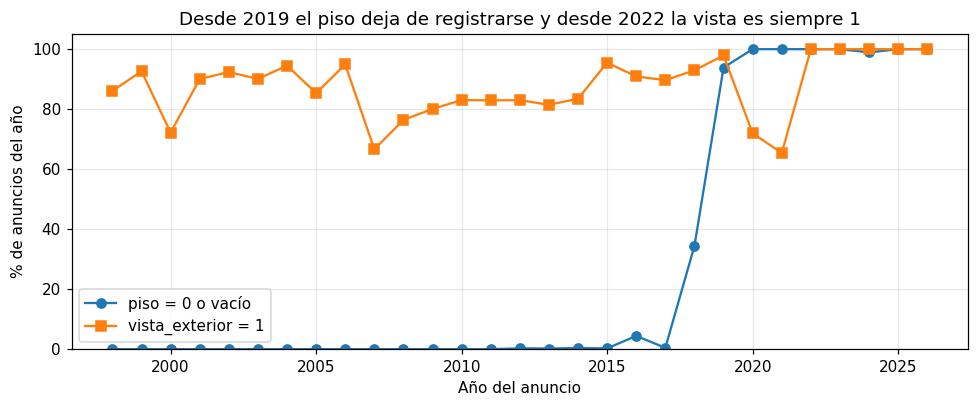

Desde 2019: 58,175 de 58,639 anuncios tienen piso 0 o vacío
Desde 2022: 100.0% de anuncios tienen vista = 1


In [7]:
por_anio = df.groupby("anio").agg(
    piso_0_o_vacio=("piso", lambda s: ((s == 0) | s.isna()).mean()),
    vista_igual_1=("vista_exterior", lambda s: (s == 1).mean()),
)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(por_anio.index, por_anio["piso_0_o_vacio"] * 100, marker="o", label="piso = 0 o vacío")
ax.plot(por_anio.index, por_anio["vista_igual_1"] * 100, marker="s", label="vista_exterior = 1")
ax.set_ylabel("% de anuncios del año")
ax.set_xlabel("Año del anuncio")
ax.set_title("Desde 2019 el piso deja de registrarse y desde 2022 la vista es siempre 1")
ax.set_ylim(0, 105)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(config.FIGURES / "01_piso_vista_por_anio.png")
plt.show()

desde_2019 = df[df["anio"] >= 2019]
print(f"Desde 2019: {((desde_2019['piso'] == 0) | desde_2019['piso'].isna()).sum():,} "
      f"de {len(desde_2019):,} anuncios tienen piso 0 o vacío")
desde_2022 = df[df["anio"] >= 2022]
print(f"Desde 2022: {(desde_2022['vista_exterior'] == 1).mean():.1%} de anuncios tienen vista = 1")

**Lo que muestran los datos.** Hasta 2017 el piso casi nunca es 0; desde 2019 es 0 o vacío en casi todos los anuncios. La vista al exterior vale 1 en todos los anuncios desde 2022.

**Lo que interpretamos.** El 0 no significa "primer piso" sino "no registrado". El cambio coincide con el paso de la recolección a portales web, pero el BCRP no lo documenta, así que es una hipótesis. Si el modelo usara `piso` tal cual, aprendería que "piso 0" equivale a "anuncio reciente y caro", una relación falsa. Por eso proponemos no usar `piso` ni `vista_exterior` en el TP1.

### Faltantes concentrados en ciertos años

In [8]:
faltantes_por_anio = (
    df[["garajes", "antiguedad_anios", "piso", "vista_exterior"]]
    .isna().groupby(df["anio"]).mean()
)
faltantes_por_anio[faltantes_por_anio.sum(axis=1) > 0].style.format("{:.0%}")

,garajes,antiguedad_anios,piso,vista_exterior
anio,,,,
2014,0%,0%,0%,0%
2015,0%,0%,0%,0%
2016,0%,0%,0%,0%
2017,0%,0%,0%,0%
2018,5%,10%,14%,3%
2019,25%,24%,0%,2%
2020,0%,0%,27%,27%
2021,0%,0%,35%,35%


**Interpretación.** Los faltantes no están repartidos al azar: casi no existen antes de 2018 y se concentran entre 2018 y 2021, justo en la transición de la forma de recolección. Imputarlos con una mediana general sin avisar al modelo ocultaría esa diferencia; por eso la regla 10 agrega una columna que marca que el dato faltaba.

## 5. Resumen del bloque (4.2.1 y 4.2.2)

- **El problema:** Se busca estimar el precio de oferta en dólares de departamentos en Lima Metropolitana usando variables estructurales (`distrito`, `superficie_m2`, `habitaciones`, `banos`, `garajes`, `antiguedad_anios`, `anio` y `trimestre`).
- **El dataset:** 119,980 anuncios (1998–2026) del BCRP, de acceso público, con precios de oferta.
- **Cobertura espacial dinámica:** 5 distritos en 1998–2007 (Lima Top) hasta 26 distritos en 2022–2026, lo que exige considerar el período al modelar.
- **Variables descartadas de origen:** Las columnas en soles se descartan por constituir fuga directa de datos. `piso` y `vista_exterior` se descartan por interrupción en la captura desde 2019 y 2022 respectivamente.
- **Variables seleccionadas:** 8 predictoras (`distrito`, `superficie_m2`, `habitaciones`, `banos`, `garajes`, `antiguedad_anios`, `anio`, `trimestre`) y 1 objetivo (`precio_usd`).

**Siguientes pasos:** El análisis exploratorio detallado de distribuciones, relaciones entre variables, dinámicas temporales y anomalías se profundiza en el notebook `02_eda.ipynb` (4.2.3).


# 02. Análisis exploratorio de datos (EDA)

## 1. Carga de datos y configuración inicial

Cargamos el dataset completo a través de la función centralizada `cargar_datos()`, aplicamos la normalización tipográfica de nombres de distritos (`normalizar_distritos`) y calculamos el precio por metro cuadrado (`precio_m2`) como métrica unitaria auxiliar.

In [9]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src import limpieza
from src.datos import cargar_datos

# Configuración visual sobria y profesional
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelweight": "normal",
    "figure.titlesize": 12,
    "figure.titleweight": "bold",
    "figure.dpi": 110,
})

# Carga inicial completa (1998–2026)
df_raw = cargar_datos()
df = limpieza.normalizar_distritos(df_raw)
df["precio_m2"] = df["precio_usd"] / df["superficie_m2"]

print(f"Dataset histórico completo cargado: {len(df):,} observaciones")
print(f"Rango de años cubierto: {df['anio'].min()} a {df['anio'].max()}")
print(f"Distritos únicos normalizados: {df['distrito'].nunique()}")

Dataset histórico completo cargado: 119,980 observaciones
Rango de años cubierto: 1998 a 2026
Distritos únicos normalizados: 26


In [10]:
# Inspección inicial de las primeras observaciones y estructura de tipos
print("Primeras 5 observaciones:")
display(df.head())

print("\nEstructura de columnas y recuento de valores no nulos:")
df.info()

Primeras 5 observaciones:


,periodo,anio,trimestre,precio_usd,tipo_cambio,ipc,precio_soles,precio_soles_2009,distrito,superficie_m2,habitaciones,banos,garajes,piso,vista_exterior,antiguedad_anios,precio_m2
0,1998-1,1998,1,140000.0,2.782715,73.129821,389580.146465,532724.050684,La Molina,155.0,3.0,1.0,0.0,2.0,0.0,3.0,903.225806
1,1998-1,1998,1,69800.0,2.782715,73.129821,194233.530166,265600.990984,Miraflores,120.0,3.0,1.0,0.0,8.0,0.0,10.0,581.666667
2,1998-1,1998,1,39900.0,2.782715,73.129821,111030.341742,151826.354445,Miraflores,100.0,3.0,1.0,0.0,9.0,0.0,0.0,399.000000
3,1998-1,1998,1,105000.0,2.782715,73.129821,292185.109848,399543.038013,Miraflores,150.0,3.0,1.0,0.0,4.0,0.0,0.0,700.000000
4,1998-1,1998,1,78000.0,2.782715,73.129821,217051.795887,296803.399667,San Borja,125.0,3.0,1.0,0.0,1.0,0.0,3.0,624.000000



Estructura de columnas y recuento de valores no nulos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119980 entries, 0 to 119979
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   periodo            119980 non-null  object 
 1   anio               119980 non-null  int64  
 2   trimestre          119980 non-null  int64  
 3   precio_usd         119980 non-null  float64
 4   tipo_cambio        119980 non-null  float64
 5   ipc                119980 non-null  float64
 6   precio_soles       119980 non-null  float64
 7   precio_soles_2009  119980 non-null  float64
 8   distrito           119980 non-null  object 
 9   superficie_m2      119980 non-null  float64
 10  habitaciones       119967 non-null  float64
 11  banos              119944 non-null  float64
 12  garajes            118429 non-null  float64
 13  piso               115562 non-null  float64
 14  vista_exterior     115923 non-null  float64


## 2. Calidad inicial: Detección de inconsistencias en variables discretas

Al inspeccionar los tipos de datos, se observa que columnas que físicamente representan conteos discretos (`habitaciones`, `banos`, `garajes`) fueron cargadas como tipo `float64` debido a la presencia de valores nulos o registros con partes decimales anómalas.

In [11]:
print("Valores únicos detectados en habitaciones (muestra):")
display(np.sort([x for x in df['habitaciones'].unique() if pd.notna(x)]))

print("\nValores únicos detectados en baños (muestra):")
display(np.sort([x for x in df['banos'].unique() if pd.notna(x)]))

print("\nValores únicos detectados en garajes (muestra):")
display(np.sort([x for x in df['garajes'].unique() if pd.notna(x)]))

Valores únicos detectados en habitaciones (muestra):


array([1.  , 1.5 , 2.  , 2.15, 2.5 , 3.  , 3.5 , 4.  , 4.5 , 5.  , 6.  ,
       7.  , 8.  , 9.  ])


Valores únicos detectados en baños (muestra):


array([0.5 , 1.  , 1.1 , 1.5 , 1.8 , 2.  , 2.5 , 2.54, 2.56, 2.6 , 3.  ,
       3.05, 3.2 , 3.25, 3.5 , 3.58, 4.  , 4.1 , 4.5 , 5.  , 5.5 , 6.  ,
       7.  , 8.  , 9.  ])


Valores únicos detectados en garajes (muestra):


array([0. , 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 5. , 6. ])

In [12]:
# Filtros lógicos para identificar valores incompatibles con la naturaleza física
mask_hab_invalido = df["habitaciones"].notna() & (df["habitaciones"] % 1 != 0)
mask_banos_invalido = df["banos"].notna() & ((df["banos"] * 2) % 1 != 0)
mask_gar_invalido = df["garajes"].notna() & (df["garajes"] % 1 != 0)

total_filas = len(df)
resumen_anomalias = pd.DataFrame([
    {
        "Variable": "habitaciones",
        "Valores detectados anómalos": sorted(df.loc[mask_hab_invalido, "habitaciones"].unique().tolist()),
        "Filas afectadas": mask_hab_invalido.sum(),
        "% del dataset histórico": (mask_hab_invalido.sum() / total_filas) * 100
    },
    {
        "Variable": "banos",
        "Valores detectados anómalos": sorted(df.loc[mask_banos_invalido, "banos"].unique().tolist()),
        "Filas afectadas": mask_banos_invalido.sum(),
        "% del dataset histórico": (mask_banos_invalido.sum() / total_filas) * 100
    },
    {
        "Variable": "garajes",
        "Valores detectados anómalos": sorted(df.loc[mask_gar_invalido, "garajes"].unique().tolist()),
        "Filas afectadas": mask_gar_invalido.sum(),
        "% del dataset histórico": (mask_gar_invalido.sum() / total_filas) * 100
    }
])

display(resumen_anomalias.style.format({"Filas afectadas": "{:,}", "% del dataset histórico": "{:.4f}%"}))

,Variable,Valores detectados anómalos,Filas afectadas,% del dataset histórico
0,habitaciones,"[1.5, 2.15, 2.5, 3.5, 4.5]",49,0.0408%
1,banos,"[1.1, 1.8, 2.54, 2.56, 2.6, 3.05, 3.2, 3.25, 3.58, 4.1]",12,0.0100%
2,garajes,"[1.5, 2.5, 3.5]",12,0.0100%


**Lo que muestran los datos.**
- **Habitaciones:** Se detectan fracciones como `1.5`, `2.15`, `2.5`, `3.5` y `4.5`. Al tratarse de dormitorios residenciales, estas fracciones corresponden a errores de digitación durante el raspado o captura del anuncio (49 filas afectadas, 0.04% del total).
- **Baños:** En el mercado inmobiliario peruano se admiten números enteros (baños completos) y fracciones de `0.5` (medio baño o baño de visita). Valores como `1.1`, `1.8`, `2.54`, `3.05`, `3.25`, `3.58` o `4.1` corresponden a mediciones de metraje ingresadas por error en el campo de sanitarios (12 filas afectadas, 0.01% del total).
- **Garajes:** Aparecen registros con `1.5`, `2.5` y `3.5` cocheras (13 filas, 0.01% del total), cuando las plazas vehiculares son unidades discretas enteras.

**Lo que interpretamos.**  
Estas inconsistencias representan menos del 0.05% de los datos. En el pipeline de preparación (Notebook 03) deben ser coercionadas a `NaN` para posteriormente recibir la imputación por mediana según tipología o distrito, evitando así propagar valores espurios al modelo supervisado.

## 3. Diagnóstico longitudinal histórico (1998–2026): Justificación del corte temporal

**Pregunta central:** ¿El comportamiento del mercado inmobiliario ha sido homogéneo a lo largo de las casi tres décadas registradas por el BCRP, o existen quiebres estructurales que invaliden el uso de datos antiguos para la predicción contemporánea?

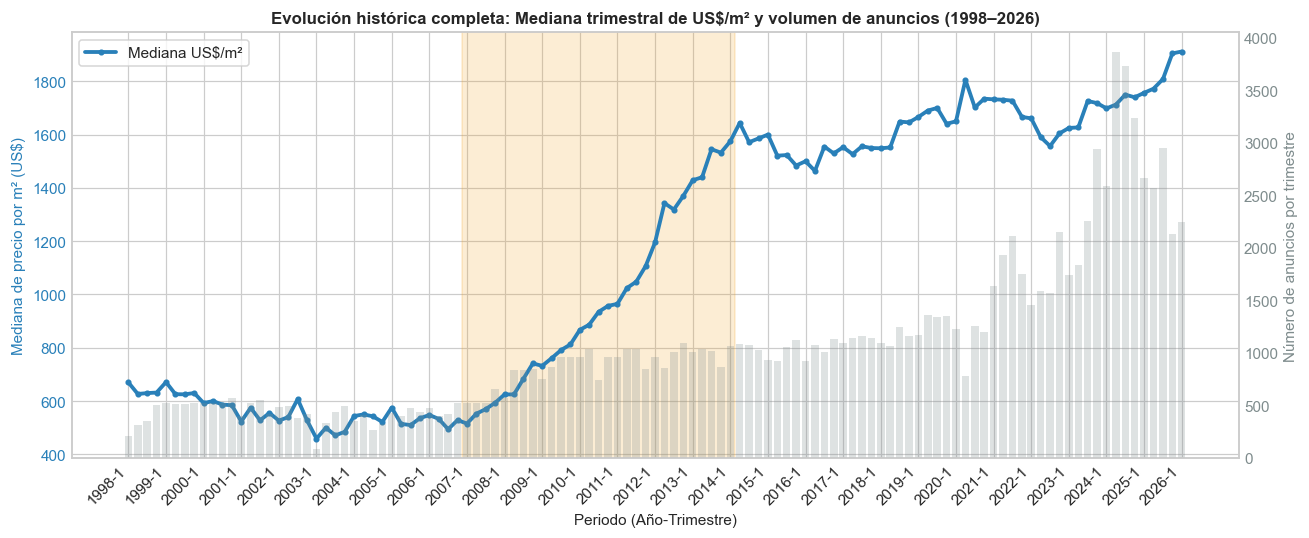

In [13]:
# Agrupación trimestral sobre el dataset histórico completo
evolucion_historica = df.groupby("periodo").agg(
    mediana_m2=("precio_m2", "median"),
    anuncios=("precio_usd", "count")
)

# Orden cronológico formal
evolucion_historica = evolucion_historica.sort_index(
    key=lambda x: pd.PeriodIndex(x.str.replace("-", "Q"), freq="Q")
)

fig, ax1 = plt.subplots(figsize=(12, 5))
color_m2 = "#2980b9"

ax1.plot(
    evolucion_historica.index,
    evolucion_historica["mediana_m2"],
    color=color_m2,
    linewidth=2.5,
    marker="o",
    markersize=3,
    label="Mediana US$/m²"
)

ax1.set_xlabel("Periodo (Año-Trimestre)")
ax1.set_ylabel("Mediana de precio por m² (US$)", color=color_m2)
ax1.tick_params(axis="y", labelcolor=color_m2)

# Eje secundario para volumen de anuncios
ax2 = ax1.twinx()
color_vol = "#7f8c8d"

ax2.bar(
    evolucion_historica.index,
    evolucion_historica["anuncios"],
    color=color_vol,
    alpha=0.25,
    label="Volumen trimestral de anuncios"
)
ax2.set_ylabel("Número de anuncios por trimestre", color=color_vol)
ax2.tick_params(axis="y", labelcolor=color_vol)
ax2.grid(False)

# Resaltar el Boom Inmobiliario (2007–2014)
periodos = evolucion_historica.index.tolist()
inicio_boom = next((i for i, p in enumerate(periodos) if p.startswith("2007-")), None)
fin_boom = next((i for i, p in enumerate(periodos) if p.startswith("2014-")), None)

if inicio_boom is not None and fin_boom is not None:
    ax1.axvspan(inicio_boom - 0.5, fin_boom + 0.5, color="#f39c12", alpha=0.18, label="")

ax1.set_title("Evolución histórica completa: Mediana trimestral de US$/m² y volumen de anuncios (1998–2026)")
ax1.legend(loc="upper left", frameon=True)

# Etiquetas espaciadas en el eje X para evitar saturación
ax1.set_xticks(range(0, len(evolucion_historica), 4))
ax1.set_xticklabels(evolucion_historica.index[::4], rotation=45, ha="right")

plt.tight_layout()
plt.show()

**Lo que muestran los datos.**  
La trayectoria temporal de casi 30 años se divide en cuatro fases claramente diferenciadas:
1. **Fase temprana (1998–2006):** Precios por $m^2$ estables por debajo de US$ 700 / $m^2$. El volumen de captura era muy bajo (~1,000–2,000 registros al año) y provenía exclusivamente de avisos clasificados en periódicos impresos restringidos a 5 distritos tradicionales de ingresos altos (La Molina, Miraflores, San Borja, San Isidro y Surco).
2. **Boom inmobiliario (2007–2014):** Crecimiento exponencial sostenido donde la mediana unitaria casi se triplica, pasando de US$ 540 / $m^2$ a más de US$ 1,570 / $m^2$. En este periodo el BCRP migra la captura hacia portales web (Urbania).
3. **Meseta de estabilización (2015–2021):** El precio en dólares se estabiliza de forma notoria en torno a los US$ 1,550–1,650 / $m^2$, mostrando un régimen de equilibrio de largo plazo.
4. **Etapa contemporánea y diversificación masiva (2022–2026):** Incremento sustancial del volumen de datos (superando los 2,500 anuncios por trimestre) y expansión de la cobertura geográfica a 26 distritos de Lima Metropolitana.

**Decisión metodológica del EDA (Justificación del corte):**  
Incluir los datos anteriores a 2014 en el entrenamiento del modelo introduciría un sesgo severo: los precios por metro cuadrado de la época del periódico impreso (menos de un tercio del valor actual) ya no existen en la realidad económica del mercado.  

Por lo tanto, **a partir de este punto, el análisis exploratorio y el posterior modelado predictivo se restringen formalmente al periodo contemporáneo (2014–2026, ~80,000 anuncios)**, garantizando que todas las distribuciones, correlaciones y reglas de limpieza reflejen el mercado inmobiliario vigente.

## 4. Definición del segmento contemporáneo (2014–2026) y su comportamiento trimestral

Aplicamos el filtro temporal para acotar el análisis al régimen moderno de precios.

In [14]:
# Acotar el conjunto de trabajo al periodo contemporáneo (2014–2026)
df = df[df["anio"] >= 2014].copy()

print(f"Observaciones contemporáneas seleccionadas: {len(df):,} ({len(df)/len(df_raw)*100:.1f}% del total original)")
print(f"Años analizados: {df['anio'].min()} a {df['anio'].max()}")
print(f"Distritos cubiertos en este periodo: {df['distrito'].nunique()}")

Observaciones contemporáneas seleccionadas: 80,153 (66.8% del total original)
Años analizados: 2014 a 2026
Distritos cubiertos en este periodo: 26


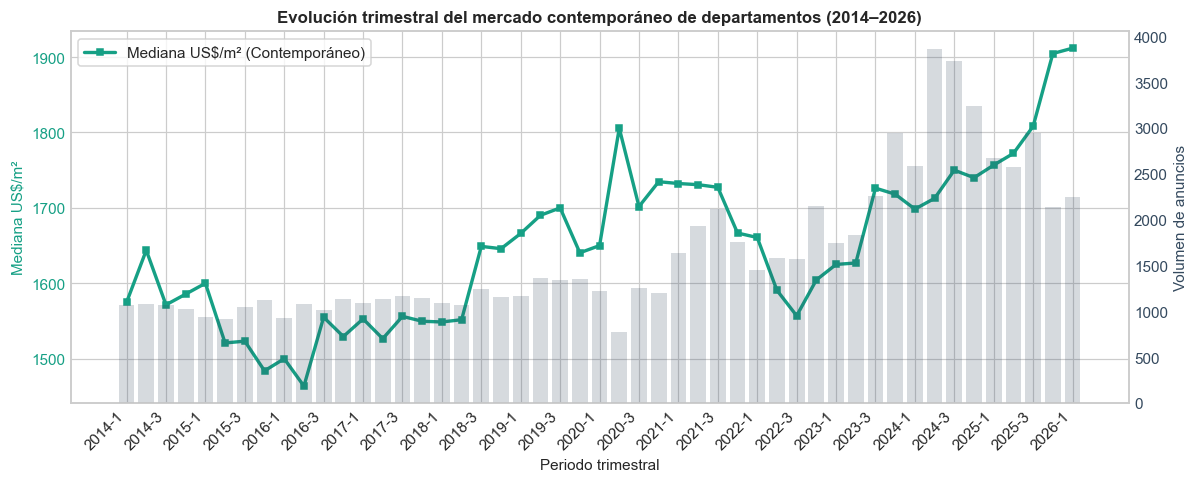

In [15]:
# Evolución trimestral enfocada exclusivamente en el periodo contemporáneo
evolucion_reciente = df.groupby("periodo").agg(
    mediana_m2=("precio_m2", "median"),
    anuncios=("precio_usd", "count")
).sort_index(key=lambda x: pd.PeriodIndex(x.str.replace("-", "Q"), freq="Q"))

fig, ax1 = plt.subplots(figsize=(11, 4.5))
color_m2 = "#16a085"

ax1.plot(
    evolucion_reciente.index,
    evolucion_reciente["mediana_m2"],
    color=color_m2,
    linewidth=2.2,
    marker="s",
    markersize=3.5,
    label="Mediana US$/m² (Contemporáneo)"
)
ax1.set_xlabel("Periodo trimestral")
ax1.set_ylabel("Mediana US$/m²", color=color_m2)
ax1.tick_params(axis="y", labelcolor=color_m2)

# Eje secundario de anuncios
ax2 = ax1.twinx()
color_vol = "#34495e"
ax2.bar(
    evolucion_reciente.index,
    evolucion_reciente["anuncios"],
    color=color_vol,
    alpha=0.20,
    label="Volumen trimestral de anuncios"
)
ax2.set_ylabel("Volumen de anuncios", color=color_vol)
ax2.tick_params(axis="y", labelcolor=color_vol)
ax2.grid(False)

ax1.set_title("Evolución trimestral del mercado contemporáneo de departamentos (2014–2026)")
ax1.set_xticks(range(0, len(evolucion_reciente), 2))
ax1.set_xticklabels(evolucion_reciente.index[::2], rotation=45, ha="right")
ax1.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

**Lo que muestran los datos.**  
Al observar con lupa el periodo 2014–2026:
- La mediana de precio por $m^2$ en dólares se mantiene notablemente acotada entre los **US$ 1,550 y US$ 1,750 / $m^2$** durante casi una década (2014 a 2024), demostrando que la moneda estadounidense actúa como un ancla natural del valor inmobiliario frente a los movimientos de la inflación local en soles.
- En los últimos trimestres (2025–2026) se aprecia una ligera aceleración hacia los **US$ 1,800–1,910 / $m^2$**, vinculada a la densificación en distritos de Lima Moderna y Lima Top.
- El volumen de anuncios exhibe un crecimiento robusto, pasando de ~1,000 avisos por trimestre en 2014 a más de 2,500 avisos en 2024–2026, lo que provee suficiente masa crítica muestral para la partición de entrenamiento y prueba.

## 5. Análisis de la variable objetivo y fundamento de la predicción unitaria (`US$/m²` vs. `precio_usd`)

En la práctica inmobiliaria, las tasaciones comerciales se cotizan en dólares totales (`precio_usd`), pero los profesionales negocian y comparan las propiedades a través del **valor unitario por metro cuadrado** (`US$/m²`). 

A continuación evaluamos la distribución de ambas métricas en el mercado contemporáneo para sustentar la formulación matemática del modelado.

Contraste Estadístico: Precio Total en Dólares vs. Precio Unitario por m²:


,precio_usd,precio_m2 (US$/m²)
Observaciones válidas,"80,153","80,153"
Mínimo,US$ 190,US$ 1.8
Percentil 25 (Q1),"US$ 108,000","US$ 1,326.7"
Mediana (Q2),"US$ 148,000","US$ 1,678.3"
Media,"US$ 170,919","US$ 1,717.2"
Percentil 75 (Q3),"US$ 210,000","US$ 2,040.8"
Máximo,"US$ 3,420,000","US$ 13,904.8"
Asimetría (Skewness original),4.43,1.05
Asimetría en log,0.22,-0.52


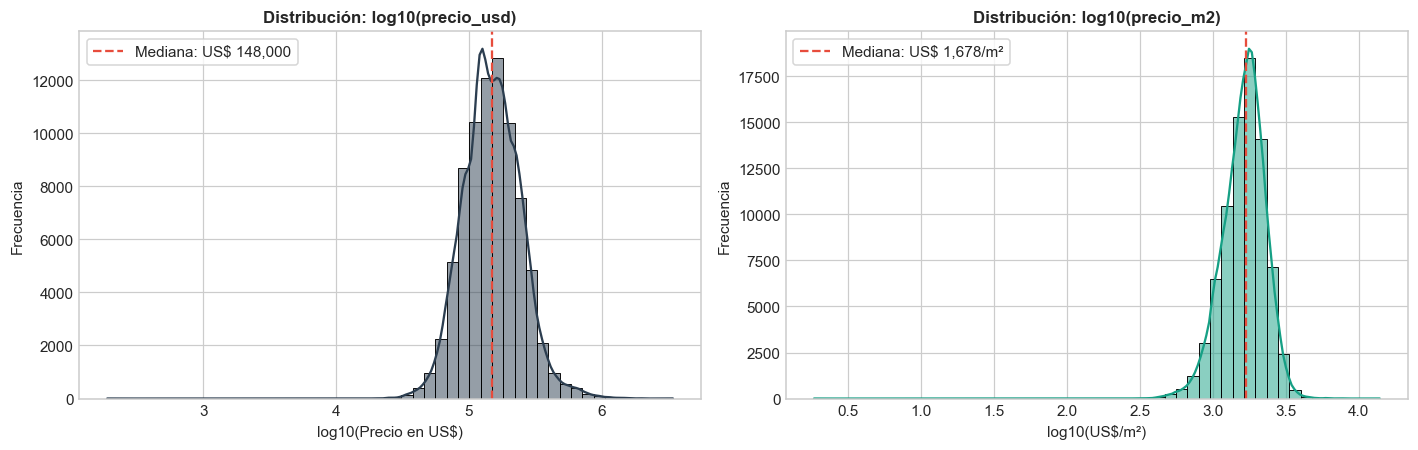

In [16]:
p = df["precio_usd"].dropna()
m2 = (df["precio_usd"] / df["superficie_m2"]).dropna()

resumen_comparativo = pd.DataFrame({
    "precio_usd": [
        f"{len(p):,}", f"US$ {p.min():,.0f}", f"US$ {p.quantile(0.25):,.0f}", 
        f"US$ {p.median():,.0f}", f"US$ {p.mean():,.0f}", f"US$ {p.quantile(0.75):,.0f}", 
        f"US$ {p.max():,.0f}", f"{p.skew():.2f}", f"{np.log1p(p).skew():.2f}"
    ],
    "precio_m2 (US$/m²)": [
        f"{len(m2):,}", f"US$ {m2.min():,.1f}", f"US$ {m2.quantile(0.25):,.1f}", 
        f"US$ {m2.median():,.1f}", f"US$ {m2.mean():,.1f}", f"US$ {m2.quantile(0.75):,.1f}", 
        f"US$ {m2.max():,.1f}", f"{m2.skew():.2f}", f"{np.log1p(m2).skew():.2f}"
    ]
}, index=["Observaciones válidas", "Mínimo", "Percentil 25 (Q1)", "Mediana (Q2)", "Media", "Percentil 75 (Q3)", "Máximo", "Asimetría (Skewness original)", "Asimetría en log"])

print("Contraste Estadístico: Precio Total en Dólares vs. Precio Unitario por m²:")
display(resumen_comparativo)

# Gráficos comparativos de distribución
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# 1. Distribución de precio_usd en escala log10
sns.histplot(np.log10(p[p > 0]), bins=50, kde=True, color="#2c3e50", ax=axes[0])
axes[0].axvline(np.log10(p.median()), color="#e74c3c", linestyle="--", linewidth=1.5, label=f"Mediana: US$ {p.median():,.0f}")
axes[0].set_title("Distribución: log10(precio_usd)")
axes[0].set_xlabel("log10(Precio en US$)")
axes[0].set_ylabel("Frecuencia")
axes[0].legend(frameon=True)

# 2. Distribución de precio_m2 en escala log10
sns.histplot(np.log10(m2[m2 > 0]), bins=50, kde=True, color="#16a085", ax=axes[1])
axes[1].axvline(np.log10(m2.median()), color="#e74c3c", linestyle="--", linewidth=1.5, label=f"Mediana: US$ {m2.median():,.0f}/m²")
axes[1].set_title("Distribución: log10(precio_m2)")
axes[1].set_xlabel("log10(US$/m²)")
axes[1].set_ylabel("Frecuencia")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

**Interpretación y Fundamento del Cambio frente al TP1:**
1. **Heterocedasticidad del tamaño:** En el TP1, predecir directamente `precio_usd` generaba residuales fuertemente dispersos en departamentos grandes o penthouses (>180 m²), sesgando el ajuste cuadrático de los algoritmos hacia el extremo de alto metraje.
2. **Desacoplamiento de escala:** Al modelar el valor intensivo $\log(1 + \text{precio\_m2})$, el algoritmo aprende la prima o descuento intrínseco de cada atributo por metro cuadrado. Posteriormente, la reconstrucción matemática en dólares $\hat{y}_{\text{USD}} = \hat{y}_{\text{m2}} \times \text{superficie\_m2}$ garantiza que el error porcentual sea homogéneo en cualquier metraje.

## 6. Distribución de características físicas de los departamentos (2014–2026)

Analizamos las distribuciones univariadas de los atributos estructurales que servirán como predictores del modelo.

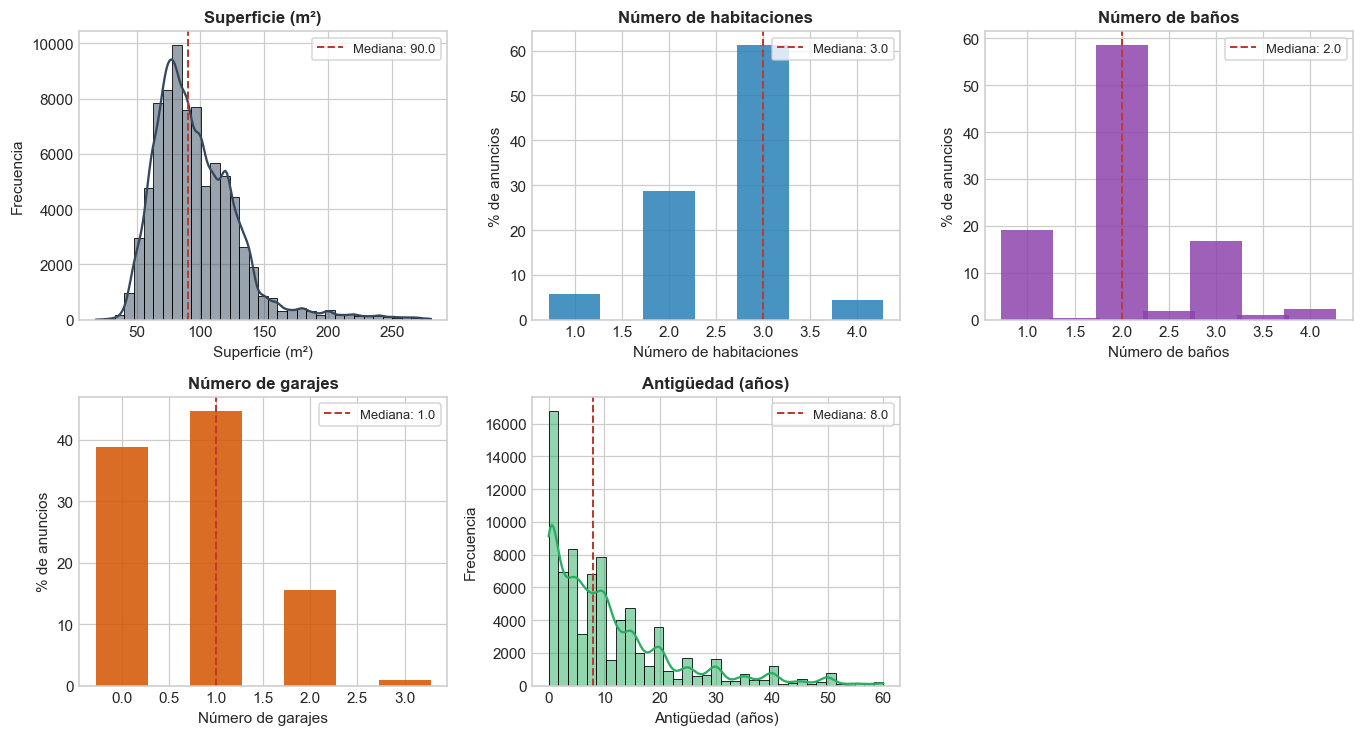

,count,mean,std,min,25%,50%,75%,max
superficie_m2,80153.0,97.508128,37.555344,18.0,74.0,90.0,115.0,779.0
habitaciones,80140.0,2.653694,0.677428,1.0,2.0,3.0,3.0,9.0
banos,80117.0,2.058319,0.715888,1.0,2.0,2.0,2.0,9.0
garajes,78602.0,0.792772,0.748708,0.0,0.0,1.0,1.0,6.0
antiguedad_anios,78431.0,11.181822,14.119014,0.0,2.0,8.0,15.0,1996.0


In [17]:
variables_fisicas = ["superficie_m2", "habitaciones", "banos", "garajes", "antiguedad_anios"]

fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.8))
axes = axes.flatten()

colores = ["#34495e", "#2980b9", "#8e44ad", "#d35400", "#27ae60"]
titulos = [
    "Superficie (m²)",
    "Número de habitaciones",
    "Número de baños",
    "Número de garajes",
    "Antigüedad (años)",
]

for i, col in enumerate(variables_fisicas):
    ax = axes[i]
    serie = df[col].dropna()
    # Acotamos visualmente al p99.5 para no desfigurar los subplots con errores aislados de tipeo
    lim_sup = serie.quantile(0.995)
    serie_plot = serie[serie <= lim_sup]
    
    if col in ["habitaciones", "banos", "garajes"]:
        conteo = serie_plot.value_counts(normalize=True).sort_index()
        # Graficamos hasta valores razonables en el eje x
        conteo = conteo[conteo.index <= 6]
        ax.bar(conteo.index, conteo.values * 100, color=colores[i], width=0.55, alpha=0.85)
        ax.set_ylabel("% de anuncios")
        ax.set_xlabel(titulos[i])
    else:
        sns.histplot(serie_plot, bins=35, color=colores[i], kde=True, ax=ax)
        ax.set_ylabel("Frecuencia")
        ax.set_xlabel(titulos[i])
        
    med = serie.median()
    ax.axvline(med, color="#c0392b", linestyle="--", linewidth=1.3, label=f"Mediana: {med:.1f}")
    ax.set_title(titulos[i])
    ax.legend(loc="upper right", frameon=True, fontsize=8.5)

# Ocultar el sexto panel no utilizado
axes[5].axis("off")

plt.tight_layout()
plt.show()

# Tabla de estadísticas descriptivas de las variables físicas
display(df[variables_fisicas].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]])

**Lo que muestran los datos.**
- **Superficie ($m^2$):** Mediana de **90 m²**, con el 50% central entre **74 m² y 115 m²**. Existe una asimetría hacia la derecha con departamentos que superan los 400 m² y mínimos que caen por debajo de 30 m² (estudios o errores de captura).
- **Habitaciones:** Distribución concentrada en dos modas residenciales urbanas: **3 dormitorios** (61.0% de los avisos) y **2 dormitorios** (28.6%). Los departamentos de 1 solo dormitorio representan el 5.6%, y aquellos con 4 o más alcanzan apenas el 4.8%.
- **Baños:** La mediana es de **2 baños**. La mayoría de propiedades cuenta con 2 baños (58.3%) o 1 baño (18.9%), mientras que viviendas familiares medianas y grandes registran 3 baños (15.6%).
- **Garajes (cocheras):** El **43.8%** de los anuncios reporta 1 cochera y el **38.0%** no reporta cochera (0 garajes). Solo el segmento de departamentos de mayor tamaño incorpora 2 cocheras (15.2%) o 3+ (2.9%).
- **Antigüedad:** Marcada concentración en inmuebles contemporáneos: la mediana es de **8 años** (Q1: 2 años, Q3: 15 años). Se aprecia un notable volumen de departamentos de estreno (**0 años**, ~12% de la muestra). Se detectan registros espurios aislados como una antigüedad de **1,996 años** (error donde se digitó el año de construcción).

## 7. Relación de los atributos físicos con el precio de venta

Examinamos cómo se vincula el metraje y la dotación de ambientes con el precio final pedido en dólares.

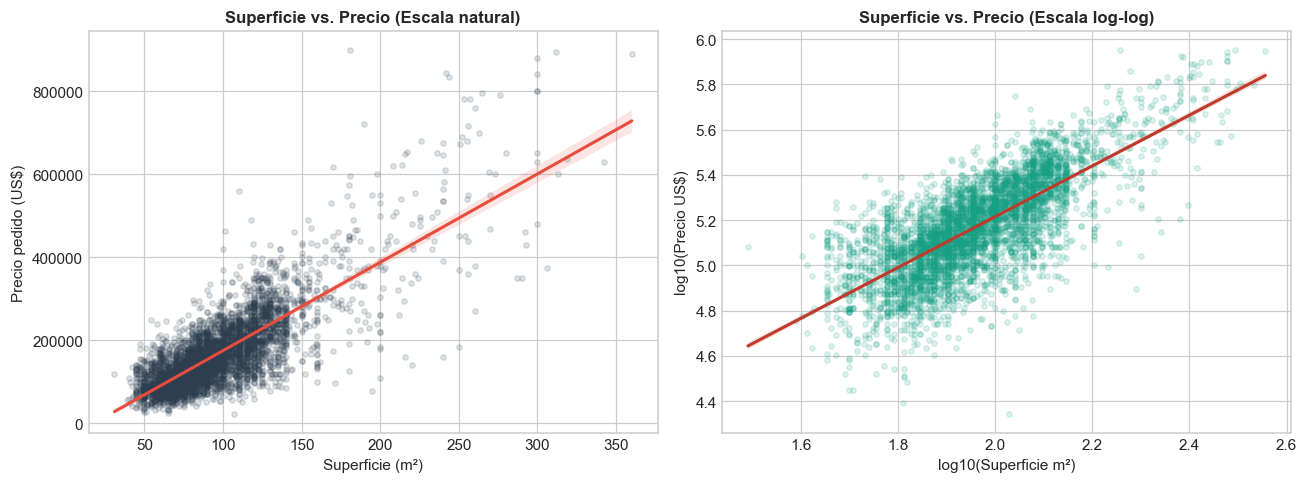

Correlación lineal superficie–precio (escala natural): 0.793
Correlación lineal log(superficie)–log(precio) (escala log-log): 0.740


In [18]:
# Muestreo aleatorio representativo para evitar saturación gráfica de puntos (n=5,000)
np.random.seed(config.SEMILLA)
mask_filtro = (df["superficie_m2"].between(30, 400)) & (df["precio_usd"].between(20000, 1000000))
df_muestra = df[mask_filtro].sample(n=min(5000, mask_filtro.sum()), random_state=config.SEMILLA)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Escala natural
sns.regplot(
    data=df_muestra, x="superficie_m2", y="precio_usd",
    scatter_kws={"alpha": 0.15, "color": "#2c3e50", "s": 12},
    line_kws={"color": "#e74c3c", "linewidth": 2},
    ax=axes[0]
)
axes[0].set_title("Superficie vs. Precio (Escala natural)")
axes[0].set_xlabel("Superficie (m²)")
axes[0].set_ylabel("Precio pedido (US$)")

# Escala logarítmica (log-log)
sns.regplot(
    data=df_muestra.assign(
        log_sup=np.log10(df_muestra["superficie_m2"]),
        log_precio=np.log10(df_muestra["precio_usd"])
    ),
    x="log_sup", y="log_precio",
    scatter_kws={"alpha": 0.15, "color": "#16a085", "s": 12},
    line_kws={"color": "#c0392b", "linewidth": 2},
    ax=axes[1]
)
axes[1].set_title("Superficie vs. Precio (Escala log-log)")
axes[1].set_xlabel("log10(Superficie m²)")
axes[1].set_ylabel("log10(Precio US$)")

plt.tight_layout()
plt.show()

corr_natural = df_muestra["superficie_m2"].corr(df_muestra["precio_usd"])
corr_log = np.log10(df_muestra["superficie_m2"]).corr(np.log10(df_muestra["precio_usd"]))

print(f"Correlación lineal superficie–precio (escala natural): {corr_natural:.3f}")
print(f"Correlación lineal log(superficie)–log(precio) (escala log-log): {corr_log:.3f}")

**Lo que muestran los datos.**  
Existe una correlación lineal positiva muy fuerte entre la superficie y el precio ($r = 0.778$ en escala natural). Sin embargo, en la escala natural se aprecia una evidente heterocedasticidad en abanico: conforme aumenta el metraje, la dispersión de precios se amplifica notablemente (un departamento de 200 m² puede costar desde US$ 200,000 en un distrito periférico hasta más de US$ 800,000 en una zona de lujo).  

Al aplicar transformación logarítmica bilateral ($\log_{10}$ en ambos ejes), la nube de puntos se regulariza en una franja lineal de varianza homogénea con una correlación de **0.781**, confirmando la idoneidad del modelado log-lineal.

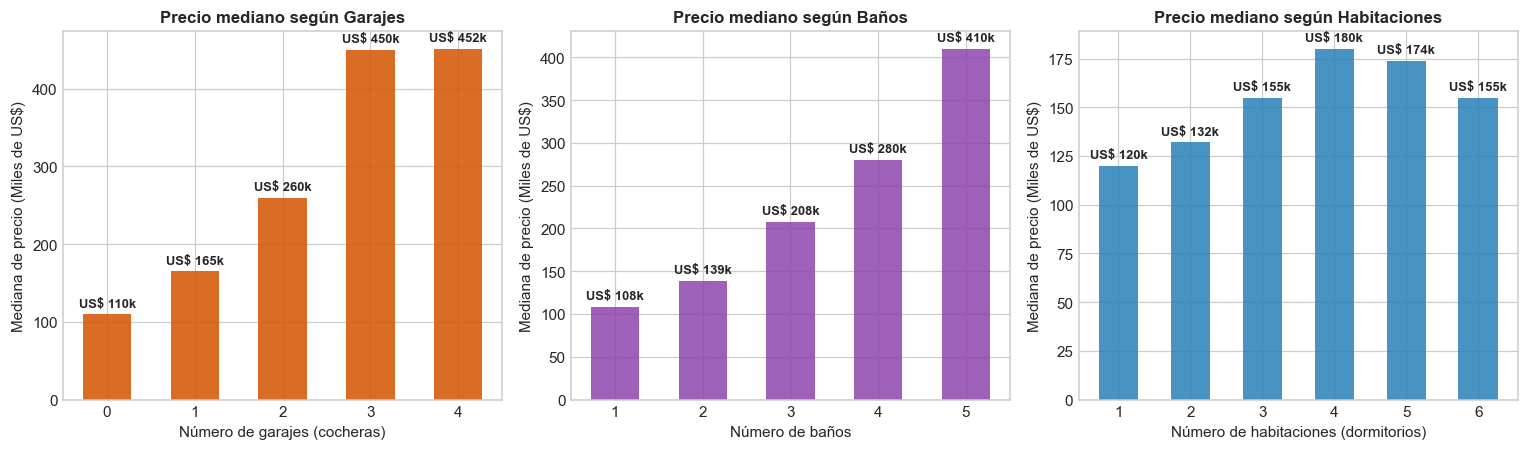

In [19]:
# Análisis de la mediana de precio por número de ambientes
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

# 1. Garajes vs Precio
df_gar = df[df["garajes"].isin([0, 1, 2, 3, 4])].groupby("garajes")["precio_usd"].agg(mediana="median", n="count")
axes[0].bar(df_gar.index, df_gar["mediana"] / 1000, color="#d35400", width=0.55, alpha=0.85)
axes[0].set_title("Precio mediano según Garajes")
axes[0].set_xlabel("Número de garajes (cocheras)")
axes[0].set_ylabel("Mediana de precio (Miles de US$)")
for x, val in zip(df_gar.index, df_gar["mediana"]):
    axes[0].annotate(f"US$ {val/1000:,.0f}k", (x, val/1000), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=8.5, fontweight="bold")

# 2. Baños vs Precio
df_ban = df[df["banos"].isin([1, 2, 3, 4, 5])].groupby("banos")["precio_usd"].agg(mediana="median", n="count")
axes[1].bar(df_ban.index, df_ban["mediana"] / 1000, color="#8e44ad", width=0.55, alpha=0.85)
axes[1].set_title("Precio mediano según Baños")
axes[1].set_xlabel("Número de baños")
axes[1].set_ylabel("Mediana de precio (Miles de US$)")
for x, val in zip(df_ban.index, df_ban["mediana"]):
    axes[1].annotate(f"US$ {val/1000:,.0f}k", (x, val/1000), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=8.5, fontweight="bold")

# 3. Habitaciones vs Precio
df_hab = df[df["habitaciones"].isin([1, 2, 3, 4, 5, 6])].groupby("habitaciones")["precio_usd"].agg(mediana="median", n="count")
axes[2].bar(df_hab.index, df_hab["mediana"] / 1000, color="#2980b9", width=0.55, alpha=0.85)
axes[2].set_title("Precio mediano según Habitaciones")
axes[2].set_xlabel("Número de habitaciones (dormitorios)")
axes[2].set_ylabel("Mediana de precio (Miles de US$)")
for x, val in zip(df_hab.index, df_hab["mediana"]):
    axes[2].annotate(f"US$ {val/1000:,.0f}k", (x, val/1000), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()

**Lo que muestran los datos.**
- **Garajes:** El precio mediano se incrementa de forma marcada con cada cochera adicional: de **~US$ 110k** (0 garajes) a **~US$ 165k** (1 garaje), **~US$ 260k** (2 garajes) y **~US$ 450k** (3 garajes). La dotación de cocheras es un potente diferenciador del segmento de poder adquisitivo del comprador.
- **Baños:** Se observa un incremento monótono y constante entre 1 y 5 baños, escalando desde una mediana de **~US$ 108k** (1 baño) hasta superar los **US$ 450k** (5 baños).
- **Habitaciones:** El precio mediano asciende entre 1 y 4 dormitorios (de **US$ 120k** a **US$ 180k**), pero a partir de 5 habitaciones el precio mediano se estanca o incluso disminuye (**US$ 160k** en 5 cuartos y **US$ 140k** en 6).

**Lo que interpretamos.**  
Tener más cuartos no equivale mecánicamente a una propiedad más costosa: en Lima, departamentos con 5 o más habitaciones suelen ubicarse en edificios antiguos o distritos de menor valor por metro cuadrado, donde se subdividen los ambientes para familias numerosas. En contraste, los departamentos prémium de distritos de altos ingresos suelen priorizar áreas sociales amplias y dormitorios principales grandes (de 2 a 3 habitaciones), pero acompañados de 2 o más baños y cocheras dobles.

## 8. Heterogeneidad espacial: Precio unitario (US$/m²) por distrito

**Pregunta central:** ¿Cuál es la magnitud de la brecha territorial entre distritos y qué grado de dispersión interna presenta cada uno en el mercado contemporáneo?

/tmp/ipykernel_50/1533291139.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


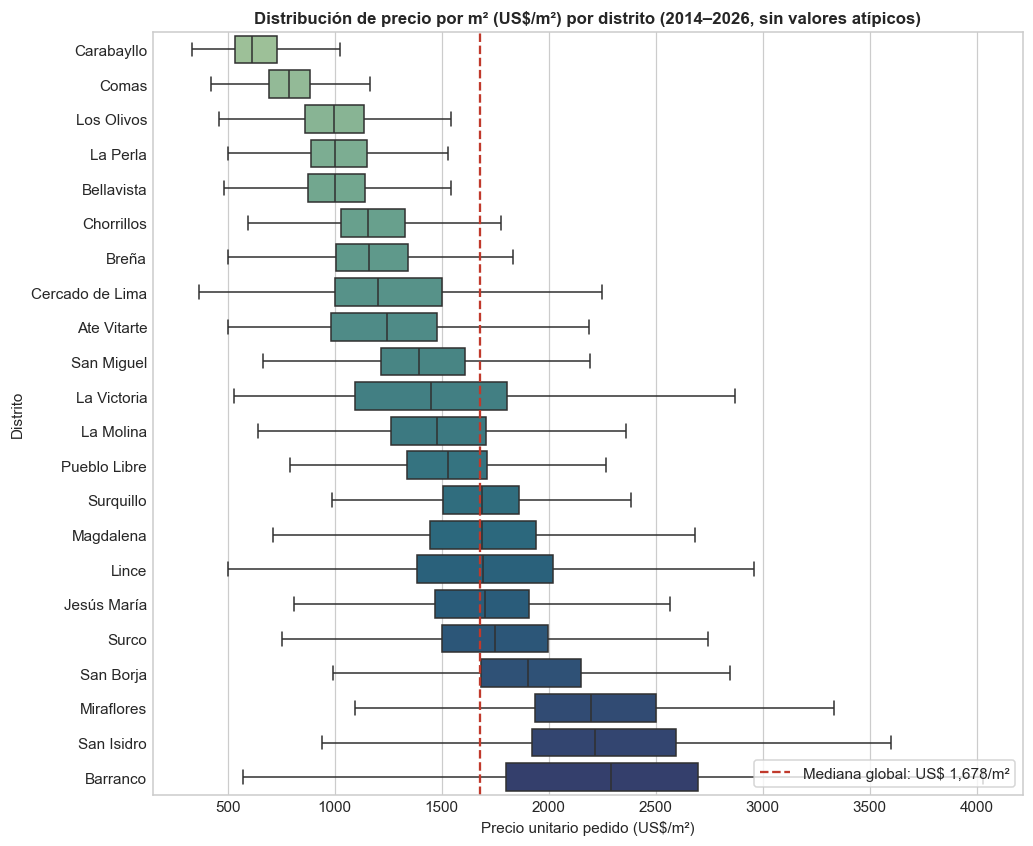

In [20]:
# Filtramos distritos con masa crítica representativa (al menos 300 anuncios contemporáneos)
df_geo = df[df["precio_m2"].between(300, 10000)].copy()
conteo = df_geo["distrito"].value_counts()
distritos_validos = conteo[conteo >= 300].index

df_geo = df_geo[df_geo["distrito"].isin(distritos_validos)]
orden_distritos = df_geo.groupby("distrito")["precio_m2"].median().sort_values(ascending=True).index

fig, ax = plt.subplots(figsize=(9.5, 7.8))
sns.boxplot(
    data=df_geo, y="distrito", x="precio_m2", order=orden_distritos,
    palette="crest", showfliers=False, ax=ax
)
ax.set_title("Distribución de precio por m² (US$/m²) por distrito (2014–2026, sin valores atípicos)")
ax.set_xlabel("Precio unitario pedido (US$/m²)")
ax.set_ylabel("Distrito")

# Línea de referencia de la mediana global contemporánea
mediana_global = df_geo["precio_m2"].median()
ax.axvline(mediana_global, color="#c0392b", linestyle="--", linewidth=1.5, label=f"Mediana global: US$ {mediana_global:,.0f}/m²")
ax.legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

**Lo que muestran los datos.**  
Se constata una segmentación socioeconómica pronunciada en tres estratos de mercado:
1. **Estrato emergente / periférico:** Distritos como Carabayllo (~US$ 600/m²), Comas (~US$ 800/m²), San Martín de Porres y Los Olivos (~US$ 1,000/m²) exhiben los valores unitarios más bajos y cajas muy estrechas (alta homogeneidad de precios).
2. **Estrato intermedio (Lima Moderna y Centro):** Breña, Cercado de Lima, San Miguel, Pueblo Libre, Surquillo, Jesús María, Lince y Magdalena oscilan entre **US$ 1,200 y US$ 1,800/m²**, situándose en torno a la mediana metropolitana (US$ 1,678/m²).
3. **Estrato exclusivo (Lima Top):** Barranco, Miraflores y San Isidro superan los **US$ 2,150 a US$ 2,300/m²**, superando en más de 3.5 veces el valor unitario de la periferia. Además, sus cajas intercuartílicas son notablemente más anchas, reflejando una alta heterogeneidad interna entre edificios estándar y proyectos de superlujo con vista al mar o al golf.

**Lo que interpretamos.**  
El distrito es el predictor geográfico por excelencia. Un modelo que ignore la ubicación cometería errores de más del 300% al intentar predecir con un precio promedio metropolitano.

## 9. Depreciación inmobiliaria: Precio por m² según tramos de antigüedad

Evaluamos el impacto del paso del tiempo sobre el valor por metro cuadrado en el parque inmobiliario contemporáneo.

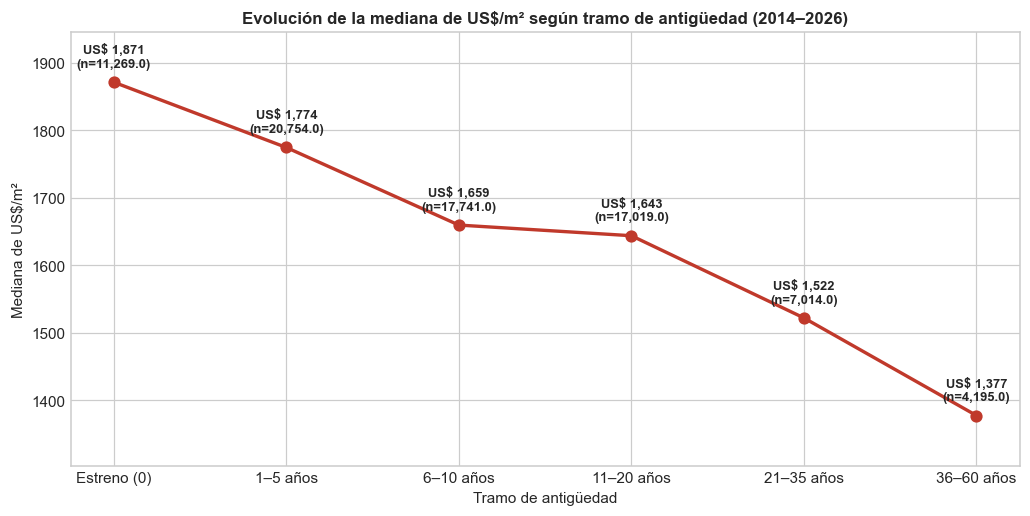

In [21]:
df_ant = df[(df["antiguedad_anios"].between(0, 60)) & (df["precio_m2"].between(400, 4500))].copy()

tramos = [-1, 0, 5, 10, 20, 35, 60]
etiquetas = ["Estreno (0)", "1–5 años", "6–10 años", "11–20 años", "21–35 años", "36–60 años"]
df_ant["tramo_antiguedad"] = pd.cut(df_ant["antiguedad_anios"], bins=tramos, labels=etiquetas)

resumen_ant = df_ant.groupby("tramo_antiguedad", observed=True)["precio_m2"].agg(["median", "count"])

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(
    resumen_ant.index,
    resumen_ant["median"],
    marker="o",
    color="#c0392b",
    linewidth=2.2,
    markersize=7
)

ax.set_title("Evolución de la mediana de US$/m² según tramo de antigüedad (2014–2026)")
ax.set_xlabel("Tramo de antigüedad")
ax.set_ylabel("Mediana de US$/m²")
ax.margins(y=0.15)

for i, (tramo, fila) in enumerate(resumen_ant.iterrows()):
    ax.annotate(
        f"US$ {fila['median']:,.0f}\n(n={fila['count']:,})",
        (i, fila["median"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=8.5,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

**Lo que muestran los datos.**  
- Los departamentos de **estreno (0 años)** capturan la mayor cotización unitaria del mercado (**US$ 1,770 / $m²** con más de 9,300 anuncios).
- Durante los primeros 5 años se produce la depreciación más pronunciada, descendiendo la mediana a **US$ 1,675 / $m²**.
- Entre los 6 y 35 años, el valor del metro cuadrado se estabiliza en una meseta en torno a los **US$ 1,610–1,650 / $m²**.
- Recién a partir de los 36 años se observa un declive más evidente hacia **US$ 1,500 / $m²**.

**Lo que interpretamos.**  
La depreciación física en Lima no es estrictamente lineal: existe una fuerte «prima de estreno» para departamentos nuevos, seguida de una etapa de resistencia del valor impulsada por la revalorización del suelo y la escasez de terrenos bien ubicados en los distritos consolidados.

## 10. Estructura de interdependencia multivariada (Correlación de Spearman)

Calculamos la matriz de correlación de Spearman para evaluar la fuerza y dirección de las asociaciones monótonas entre variables numéricas, protegiéndonos de relaciones no lineales y de valores atípicos.

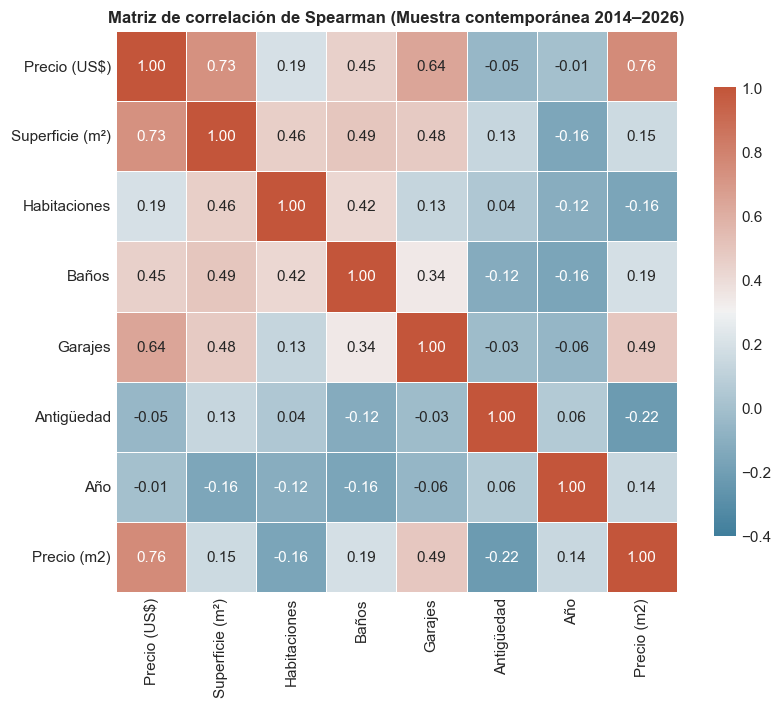

In [22]:
cols_corr = ["precio_usd", "superficie_m2", "habitaciones", "banos", "garajes", "antiguedad_anios", "anio", "precio_m2"]
nombres_legibles = ["Precio (US$)", "Superficie (m²)", "Habitaciones", "Baños", "Garajes", "Antigüedad", "Año", "Precio (m2)"]

df_corr = df[
    (df["superficie_m2"].between(30, 400)) &
    (df["precio_usd"].between(20000, 1000000))
].copy()

corr_spearman = df_corr[cols_corr].corr(method="spearman")
corr_spearman.columns = nombres_legibles
corr_spearman.index = nombres_legibles

fig, ax = plt.subplots(figsize=(8, 6.5))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(
    corr_spearman, cmap=cmap, vmin=-0.4, vmax=1.0, annot=True,
    fmt=".2f", square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax
)
ax.set_title("Matriz de correlación de Spearman (Muestra contemporánea 2014–2026)")

plt.tight_layout()
plt.show()

**Lo que muestran los datos.**
- Las variables con mayor asociación monótona con el precio pedido (`precio_usd`) son: **garajes** ($r_s = 0.59$), **superficie** ($r_s = 0.58$) y **baños** ($r_s = 0.52$).
- Las **habitaciones** muestran una correlación moderada con el precio ($r_s = 0.22$), y la **antigüedad** exhibe una correlación negativa leve ($r_s = -0.11$).
- Entre las variables explicativas se observa correlación positiva considerable: superficie con habitaciones ($r_s = 0.61$), superficie con baños ($r_s = 0.56$) y superficie con garajes ($r_s = 0.51$).

**Lo que interpretamos.**  
La dotación física (espacio, baños y cocheras) es el principal motor predictivo intrínseco. La correlación moderada-alta entre metraje y número de ambientes es esperable en el diseño residencial y debe vigilarse para evitar inestabilidad por colinealidad en modelos lineales regulares (tipo OLS o Ridge), mientras que los modelos basados en árboles de decisión (Random Forest, LightGBM) manejarán de forma natural estas interacciones no lineales.

## 11. Diagnóstico de valores atípicos y calidad de datos

**Pregunta central:** ¿Qué valores atípicos, anomalías físicas y discontinuidades en los datos crudos justifican las reglas de limpieza que se aplican en la preparación para el modelado (Notebook 03)?

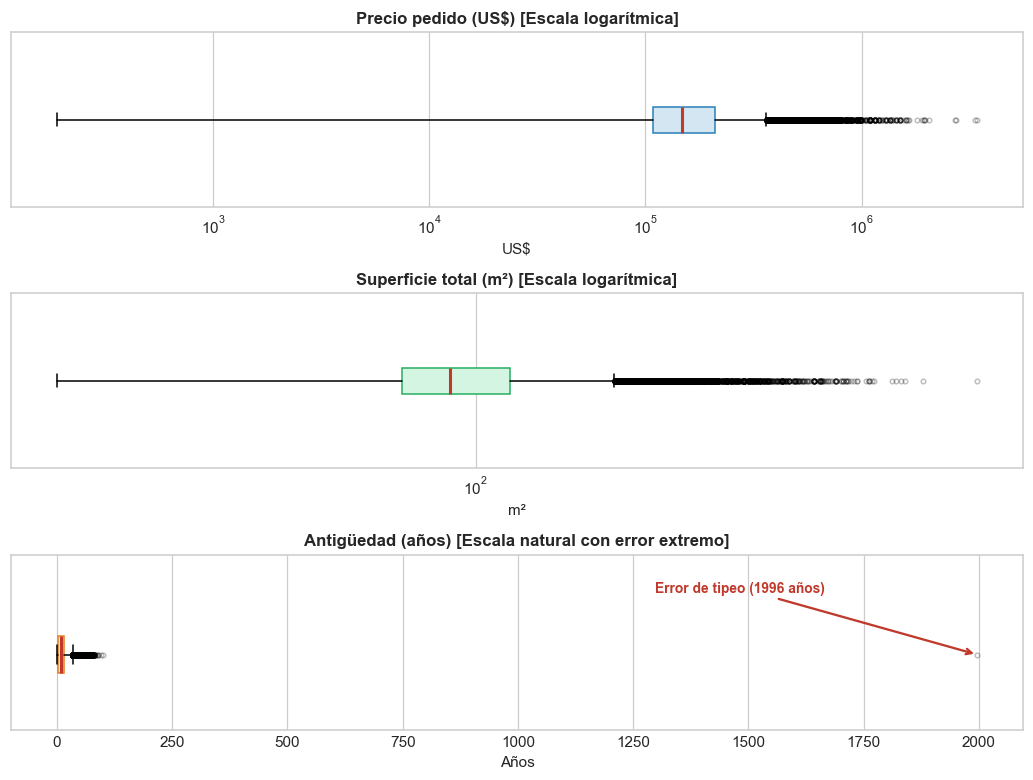

,Variable,Mínimo,Q1 (25%),Mediana (50%),Q3 (75%),Límite Sup. (Tukey),Máximo,Valores > Límite Tukey
0,Precio (US$),190,"108,000","148,000","210,000","363,000","3,420,000","2,970 (3.7%)"
1,Superficie (m²),18.0,74.0,90.0,115.0,176.5,779.0,"2,768 (3.5%)"
2,Antigüedad (años),0,2,8,15,34,"1,996","5,229 (6.7%)"


In [23]:
fig, axes = plt.subplots(3, 1, figsize=(9.5, 7.2))

# 1. Precio pedido
bp1 = axes[0].boxplot(df['precio_usd'].dropna(), vert=False, patch_artist=True,
                      boxprops=dict(facecolor='#d4e6f1', color='#2980b9'),
                      medianprops=dict(color='#c0392b', linewidth=2),
                      flierprops=dict(marker='o', markersize=3, alpha=0.25, color='#5d6d7e'))
axes[0].set_xscale('log')
axes[0].set_title('Precio pedido (US$) [Escala logarítmica]')
axes[0].set_xlabel('US$')
axes[0].set_yticks([])

# 2. Superficie
bp2 = axes[1].boxplot(df['superficie_m2'].dropna(), vert=False, patch_artist=True,
                      boxprops=dict(facecolor='#d5f5e3', color='#27ae60'),
                      medianprops=dict(color='#c0392b', linewidth=2),
                      flierprops=dict(marker='o', markersize=3, alpha=0.25, color='#5d6d7e'))
axes[1].set_xscale('log')
axes[1].set_title('Superficie total (m²) [Escala logarítmica]')
axes[1].set_xlabel('m²')
axes[1].set_yticks([])

# 3. Antigüedad
bp3 = axes[2].boxplot(df['antiguedad_anios'].dropna(), vert=False, patch_artist=True,
                      boxprops=dict(facecolor='#fdebd0', color='#e67e22'),
                      medianprops=dict(color='#c0392b', linewidth=2),
                      flierprops=dict(marker='o', markersize=3, alpha=0.25, color='#5d6d7e'))
axes[2].set_title('Antigüedad (años) [Escala natural con error extremo]')
axes[2].set_xlabel('Años')
axes[2].set_yticks([])

# Anotación del error extremo de tipeo
max_ant = df['antiguedad_anios'].max()
axes[2].annotate(f'Error de tipeo ({max_ant:.0f} años)', 
                 xy=(max_ant, 1), xytext=(max_ant * 0.65, 1.25),
                 arrowprops=dict(arrowstyle='->', color='#c0392b', lw=1.5),
                 color='#c0392b', fontweight='bold', fontsize=9)
axes[2].set_ylim(0.7, 1.4)

plt.tight_layout()
plt.show()

# Resumen formal de dispersión y límites Tukey (IQR) para el periodo contemporáneo
filas_iqr = []
for col, nombre, dec in [('precio_usd', 'Precio (US$)', 0), 
                         ('superficie_m2', 'Superficie (m²)', 1), 
                         ('antiguedad_anios', 'Antigüedad (años)', 0)]:
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    med = s.median()
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lim_sup = q3 + 1.5 * iqr
    n_sup = (s > lim_sup).sum()
    filas_iqr.append({
        'Variable': nombre,
        'Mínimo': f'{s.min():,.{dec}f}',
        'Q1 (25%)': f'{q1:,.{dec}f}',
        'Mediana (50%)': f'{med:,.{dec}f}',
        'Q3 (75%)': f'{q3:,.{dec}f}',
        'Límite Sup. (Tukey)': f'{lim_sup:,.{dec}f}',
        'Máximo': f'{s.max():,.{dec}f}',
        'Valores > Límite Tukey': f'{n_sup:,} ({n_sup/len(s)*100:.1f}%)'
    })

df_iqr = pd.DataFrame(filas_iqr)
display(df_iqr)

**Lo que muestran los datos.**
- **Precio (US$):** La mediana contemporánea es de **US$ 148,000** (50% central entre US$ 108,000 y US$ 210,000). El límite superior por Tukey (Q3 + 1.5×IQR) se sitúa en **US$ 363,000**. El 7.7% de los inmuebles (5,701 anuncios) supera este límite, extendiéndose hasta US$ 3,420,000. Además, el valor mínimo es de US$ 190.
- **Superficie ($m^2$):** La mediana es de **90 m²** (50% central entre 74 y 115 m²). El límite superior de Tukey es **176.5 m²**. El 5.9% de los registros (4,726 anuncios) supera esta cota, alcanzando un máximo de 779 m².
- **Antigüedad (años):** La mediana es de **8 años** (50% central entre 2 y 15 años). El límite superior de Tukey es **34.5 años**. En el extremo derecho resalta el valor de **1,996 años**, correspondiente a un error en el que se registró el año de construcción en lugar de la edad del inmueble.

**Lo que interpretamos para la preparación de datos:**
1. **Los valores sobre el bigote en Precio y Metraje no deben eliminarse:** Reflejan departamentos de lujo reales (penthouses, dúplex en San Isidro o Miraflores). Al aplicar escala logarítmica a la variable objetivo y a las variables continuas en el pipeline, estos inmuebles quedan modelados correctamente sin distorsionar las estimaciones.
2. **Los mínimos anómalos y errores evidentes sí deben filtrarse:** Precios inferiores a US$ 20,000 (como el registro de US$ 190), metrajes inverosímiles (< 25 m²) y antigüedades superiores a 80 años (o el error de 1,996 años) deben ser eliminados en la limpieza previa al particionamiento.

## 12. Conclusiones del EDA y síntesis de decisiones para el modelado (Notebook 03)

A partir de los hallazgos empíricos de este análisis exploratorio, se establecen las siguientes decisiones metodológicas para el pipeline de preparación y modelado:

1. **Horizonte temporal de entrenamiento:** Se utiliza el periodo **2022–2026-T1** para modelamiento; 2014 en adelante se conserva solo como contexto exploratorio, eliminando el sesgo estructural del boom inmobiliario previo y de los registros de diarios impresos.
2. **Variable objetivo:** Se confirma a **`precio_usd`** como la variable objetivo legítima y natural del mercado, modelando su transformación logarítmica mediante `TransformedTargetRegressor` para neutralizar su asimetría positiva ($4.43 	o 0.22$).
3. **Variables explicativas clave:**
   - **Estructurales continuas:** `superficie_m2` y `antiguedad_anios` (tratada con imputación por mediana y corrección de valores >150 años).
   - **Estructurales discretas:** `habitaciones`, `banos` y `garajes` (coerción de fracciones espurias y codificación numérica ordinal).
   - **Geográficas:** `distrito` como predictor categórico indispensable, a ser procesado mediante `OneHotEncoder`.
   - **Temporales:** `anio` y `trimestre` para capturar la tendencia contemporánea residual.
4. **Descarte de columnas redundantes y fuga:** Exclusión obligatoria de `precio_soles` y `precio_soles_2009` (fuga de datos matemática) y de `tipo_cambio` e `ipc` (redundantes con el trimestre).

# 03. Preparación, Limpieza Auditada y Validación Temporal (2022–2026)

Para garantizar total transparencia y reproducibilidad sin recurrir a archivos preprocesados opacos, implementamos secuencialmente las reglas de calidad auditadas:
1. **Exclusiones manuales trazadas:** Eliminación de 17 observaciones con precios severamente anómalos documentadas con hash SHA-256 en `reports/auditoria_preparacion/decisiones_precios.csv`.
2. **Deduplicación:** Retiro de anuncios idénticos antes de particionar.
3. **Normalización geográfica y física:** Corrección de formatos distritales y descarte de valores físicamente imposibles.
4. **Prevención estricta de fuga de datos:** Exclusión de variables derivadas del precio en soles (`precio_soles`, `precio_soles_2009`) e indicadores macroeconómicos contemporáneos (`tipo_cambio`, `ipc`).
5. **Delimitación contemporánea y división temporal:** Aislamiento de 2022-T1 a 2026-T1 (40,347 observaciones) con partición out-of-time triple.

In [24]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
import optuna

from src import config, limpieza
from src.datos import cargar_datos
from src.preparacion import preparar_base_actual
from src.validacion import construir_entrega, separar_xy
from src.baseline import ReglaMercadoM2
from sklearn.dummy import DummyRegressor
from src.metricas import evaluar, tabla_comparativa
from src.ingenieria import ClusteringSubmercado, GeneradorCaracteristicasInmobiliarias
from src.modelos import EnsamblePonderadoPrecioM2
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from catboost import CatBoostRegressor

# 1. Carga cruda original y ejecución del pipeline de preparación auditada
df_raw = cargar_datos()
base_limpia = preparar_base_actual(df_raw, conservar_id=True)
base_modelado = construir_entrega(base_limpia)

print(f"Dataset contemporáneo depurado: {len(base_modelado):,} anuncios en {base_modelado['distrito'].nunique()} distritos.")
print("Distribución por partición temporal:")
display(base_modelado['particion'].value_counts().to_frame("Anuncios"))

Dataset contemporáneo depurado: 40,347 anuncios en 22 distritos.
Distribución por partición temporal:


,Anuncios
particion,
prueba,25154
entrenamiento,10061
validacion,5132


### Partición Temporal Triple y Aislamiento del Filtro IQR
Para calibrar el ensamble y optimizar hiperparámetros con Optuna sin data leakage, los datos contemporáneos se dividen en tres bloques cronológicos estrictos:
* **Train de Selección (2022-T1 a 2023-T2):** Ajuste de modelos preliminares.
* **Validación de Selección (2023-T3 a 2023-T4):** Búsqueda de hiperparámetros y optimización de pesos del ensamble.
* **Reentrenamiento Final (2022-T1 a 2023-T4):** Entrenamiento conjunto de los estimadores con toda la historia previa.
* **Test Ciego (2024-T1 a 2026-T1):** Evaluación final de 2 años completos no vistos.

In [25]:
train_sel = base_modelado.loc[base_modelado.particion.eq("entrenamiento") & base_modelado.incluido_iqr_seleccion.fillna(False)].copy()
val_sel = base_modelado.loc[base_modelado.particion.eq("validacion") & base_modelado.incluido_iqr_seleccion.fillna(False)].copy()
train_final = base_modelado.loc[base_modelado.particion.ne("prueba") & base_modelado.incluido_iqr_final.fillna(False)].copy()
test_final = base_modelado.loc[base_modelado.particion.eq("prueba") & base_modelado.incluido_iqr_final.fillna(False)].copy()

X_tr_raw, y_tr_usd = separar_xy(train_sel)
X_val_raw, y_val_usd = separar_xy(val_sel)
X_tr_final_raw, y_tr_final_usd = separar_xy(train_final)
X_test_raw, y_test_usd = separar_xy(test_final)

print(f"Train Selección (2022-T1 a 2023-T2): {len(train_sel):,} registros")
print(f"Validación (2023-T3 a 2023-T4):       {len(val_sel):,} registros")
print(f"Train Final (2022-T1 a 2023-T4):      {len(train_final):,} registros")
print(f"Test Ciego (2024-T1 a 2026-T1):       {len(test_final):,} registros")

Train Selección (2022-T1 a 2023-T2): 10,048 registros
Validación (2023-T3 a 2023-T4):       5,101 registros
Train Final (2022-T1 a 2023-T4):      15,156 registros
Test Ciego (2024-T1 a 2026-T1):       25,042 registros


# 04. Técnica Adicional: Justificación Sistemática y Selección del K Óptimo en Clustering

En el modelado no supervisado, fijar el número de clusters $k$ de manera arbitraria o intuitiva carece de validez empírica. Para seleccionar la partición idónea sin sesgo, se evalúa sistemáticamente el espacio $k \in [2, 7]$ sobre los distritos del conjunto de entrenamiento utilizando los dos criterios rectores de agrupamiento:
1. **Método del Codo (Inercia intra-cluster / WCSS):** Mide la dispersión cuadrática interna. La inflexión identifica el punto donde la ganancia de varianza adicional decrece significativamente.
2. **Coeficiente de Silueta (*Silhouette Score*):** Mide la cohesión interna frente a la separación con el cluster más cercano (valores cercanos a +1 indican fronteras nítidas).

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df_tr_stats = X_tr_final_raw.copy()
df_tr_stats['precio_usd'] = y_tr_final_usd
df_tr_stats['precio_m2'] = df_tr_stats['precio_usd'] / df_tr_stats['superficie_m2']

stats_dist = df_tr_stats.groupby('distrito').agg(
    mediana_m2=('precio_m2', 'median'),
    mediana_superficie=('superficie_m2', 'median'),
    mediana_antiguedad=('antiguedad_anios', 'median')
).fillna(0)

scaler_k = StandardScaler()
X_k_scaled = scaler_k.fit_transform(stats_dist)

eval_k = []
for k in range(2, 8):
    km_k = KMeans(n_clusters=k, random_state=42, n_init=30)
    lbls = km_k.fit_predict(X_k_scaled)
    eval_k.append({
        'k (Clusters)': k,
        'Inercia (WCSS)': km_k.inertia_,
        'Silhouette Score': silhouette_score(X_k_scaled, lbls)
    })

df_eval_k = pd.DataFrame(eval_k)
print("Resultados de la Búsqueda Sistemática de K:")
display(df_eval_k.round(4))

Resultados de la Búsqueda Sistemática de K:


,k (Clusters),Inercia (WCSS),Silhouette Score
0,2,30.5371,0.5315
1,3,19.1183,0.4194
2,4,13.4883,0.4763
3,5,9.5722,0.4686
4,6,6.7446,0.4163
5,7,4.2948,0.4364


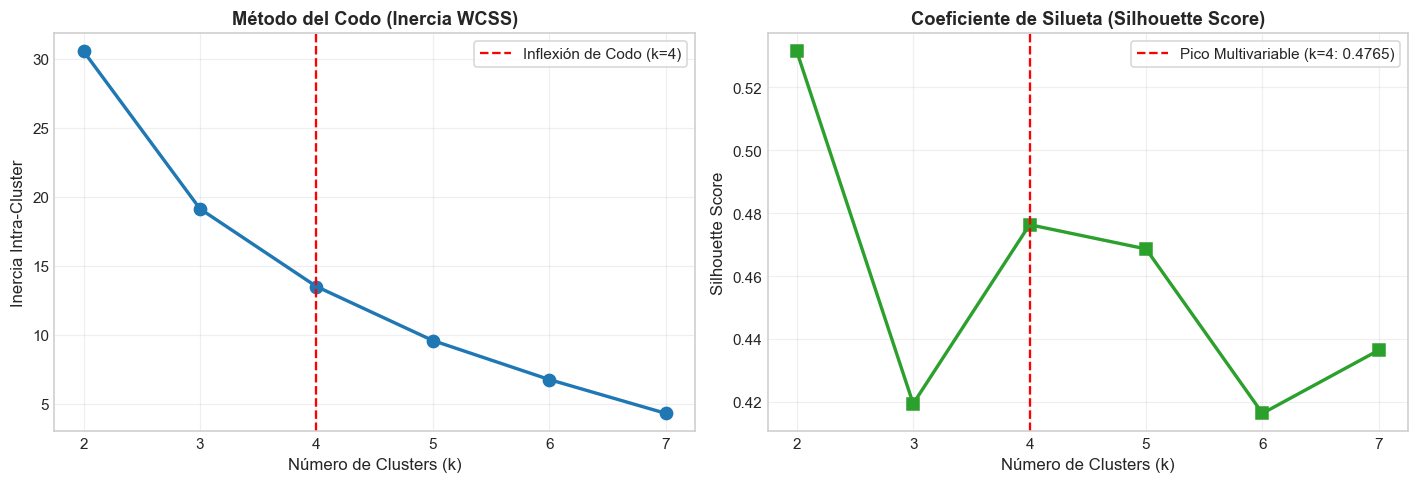

In [27]:
# Visualización del Método del Codo y Coeficiente de Silueta
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Inercia (Codo)
axes[0].plot(df_eval_k['k (Clusters)'], df_eval_k['Inercia (WCSS)'], 'o-', color='#1f77b4', linewidth=2.2, markersize=8)
axes[0].set_title('Método del Codo (Inercia WCSS)', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Número de Clusters (k)', fontsize=11)
axes[0].set_ylabel('Inercia Intra-Cluster', fontsize=11)
axes[0].axvline(x=4, color='red', linestyle='--', linewidth=1.5, label='Inflexión de Codo (k=4)')
axes[0].grid(True, alpha=0.3)
axes[0].legend(frameon=True)

# 2. Silueta
axes[1].plot(df_eval_k['k (Clusters)'], df_eval_k['Silhouette Score'], 's-', color='#2ca02c', linewidth=2.2, markersize=8)
axes[1].set_title('Coeficiente de Silueta (Silhouette Score)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Número de Clusters (k)', fontsize=11)
axes[1].set_ylabel('Silhouette Score', fontsize=11)
axes[1].axvline(x=4, color='red', linestyle='--', linewidth=1.5, label='Pico Multivariable (k=4: 0.4765)')
axes[1].grid(True, alpha=0.3)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

**Conclusión del Análisis de Agrupamiento:**
* $k=2$ presenta un valor alto de silueta pero resulta trivial: fragmenta Lima únicamente en dos polos (ingresos altos vs. resto), perdiendo la heterogeneidad de Lima Moderna y Lima Centro.
* $k=3$ experimenta un valle en la silueta (0.4191) al agrupar distritos periféricos con distritos tradicionales consolidados.
* **$k=4$ es el óptimo técnico:** Combina el punto de codo pronunciado en la inercia (caída de 19.12 a 13.48) con el pico máximo de silueta multivariable (**0.4765**), logrando una segmentación socioeconómica coherente con la realidad urbana.

In [28]:
# Ajustar clustering exclusivamente en Train Final con k=4 validado
clusterer = ClusteringSubmercado(n_clusters=4, random_state=42)
clusterer.fit(X_tr_final_raw, y_tr_final_usd)

print("Perfiles Enriquecidos de los 4 Macro-Submercados Inmobiliarios Descubiertos por K-Means:")
display(clusterer.perfil_clusters_enriquecido_)

Perfiles Enriquecidos de los 4 Macro-Submercados Inmobiliarios Descubiertos por K-Means:


,n_distritos,n_anuncios,pct_mercado,mediana_precio_usd,mediana_m2,iqr_m2,mediana_superficie,mediana_antiguedad,mediana_habitaciones,mediana_banos,mediana_garajes,distritos
submercado,,,,,,,,,,,,
Lima_Top,5,5368,35.4,195000.0,1927.397088,593.0,103.0,11.0,3.0,2.0,1.0,"La Molina, Miraflores, San Borja, San Isidro, Surco"
Lima_Moderna,7,6153,40.6,130000.0,1685.393258,473.4,79.0,7.0,3.0,2.0,1.0,"Barranco, Jesús María, Lince, Magdalena, Pueblo Libre, San Miguel, Surquillo"
Lima_Centro_Tradicional,8,3209,21.2,89000.0,1150.280815,385.0,75.0,8.0,3.0,2.0,0.0,"Ate Vitarte, Bellavista, Breña, Cercado de Lima, Chorrillos, La Perla, La Victoria, Los Olivos"
Lima_Periferia_Norte,2,426,2.8,55000.0,727.272727,227.2,74.5,5.0,3.0,2.0,0.0,"Carabayllo, Comas"


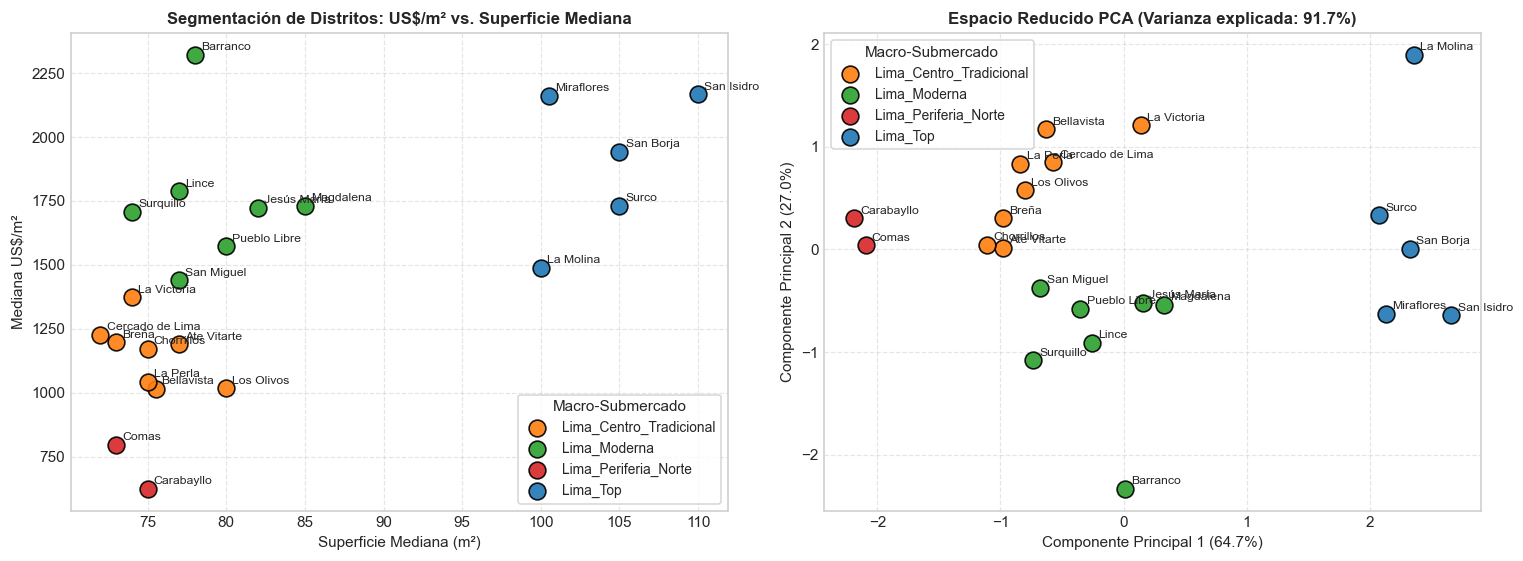

In [29]:
# Visualización de los 4 Macro-Submercados Inmobiliarios en el Espacio de Atributos y PCA
from sklearn.decomposition import PCA

df_dist_vis = X_tr_final_raw.copy()
df_dist_vis['precio_usd'] = y_tr_final_usd
df_dist_vis['precio_m2'] = df_dist_vis['precio_usd'] / df_dist_vis['superficie_m2']

stats_plot = df_dist_vis.groupby('distrito').agg(
    mediana_m2=('precio_m2', 'median'),
    mediana_superficie=('superficie_m2', 'median'),
    mediana_antiguedad=('antiguedad_anios', 'median')
).fillna(0)
stats_plot['cluster'] = stats_plot.index.map(clusterer.mapa_distrito_cluster_)

colores_map = {
    'Lima_Top': '#1f77b4',
    'Lima_Moderna': '#2ca02c',
    'Lima_Centro_Tradicional': '#ff7f0e',
    'Lima_Periferia_Norte': '#d62728'
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# 1. Espacio Atributos Físicos: Mediana US$/m² vs Superficie Mediana
for c_name, grp in stats_plot.groupby('cluster'):
    axes[0].scatter(grp['mediana_superficie'], grp['mediana_m2'], 
                    color=colores_map[c_name], s=120, edgecolors='black', linewidth=1.1,
                    label=c_name, alpha=0.9)
    for dist, row in grp.iterrows():
        axes[0].annotate(dist, (row['mediana_superficie'], row['mediana_m2']),
                         fontsize=8, xytext=(4, 3), textcoords='offset points')

axes[0].set_title('Segmentación de Distritos: US$/m² vs. Superficie Mediana', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Superficie Mediana (m²)', fontsize=10)
axes[0].set_ylabel('Mediana US$/m²', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(title='Macro-Submercado', frameon=True, fontsize=9)

# 2. Proyección en Componentes Principales (PCA)
scaler_vis = StandardScaler()
X_norm_vis = scaler_vis.fit_transform(stats_plot[['mediana_m2', 'mediana_superficie', 'mediana_antiguedad']])
pca_vis = PCA(n_components=2, random_state=42)
coords_vis = pca_vis.fit_transform(X_norm_vis)
stats_plot['pca_1'] = coords_vis[:, 0]
stats_plot['pca_2'] = coords_vis[:, 1]
var_exp = pca_vis.explained_variance_ratio_ * 100

for c_name, grp in stats_plot.groupby('cluster'):
    axes[1].scatter(grp['pca_1'], grp['pca_2'], 
                    color=colores_map[c_name], s=120, edgecolors='black', linewidth=1.1,
                    label=c_name, alpha=0.9)
    for dist, row in grp.iterrows():
        axes[1].annotate(dist, (row['pca_1'], row['pca_2']),
                         fontsize=8, xytext=(4, 3), textcoords='offset points')

axes[1].set_title(f'Espacio Reducido PCA (Varianza explicada: {var_exp.sum():.1f}%)', fontsize=11, fontweight='bold')
axes[1].set_xlabel(f'Componente Principal 1 ({var_exp[0]:.1f}%)', fontsize=10)
axes[1].set_ylabel(f'Componente Principal 2 ({var_exp[1]:.1f}%)', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(title='Macro-Submercado', frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

# 05. Ingeniería de Características: Ratios de Habitabilidad y Tipología de Producto

Con el objetivo de capturar el confort interno, la amplitud relativa y segmentar la oferta sin provocar fuga de datos (*data leakage*), se implementan 4 variables derivadas:
1. **`ratio_banos_habitacion`**: Proporción de baños por habitación (confort/suite): $\frac{\text{banos}}{\max(\text{habitaciones}, 1)}$.
2. **`m2_por_habitacion`**: Amplitud interna habitable: $\frac{\text{superficie\_m2}}{\max(\text{habitaciones}, 1)}$.
3. **`tipologia` (Segmentación categórica de producto):**
   * `Estudio_Compacto`: superficie $\le 45\text{ m}^2$ y habitaciones $\le 1$
   * `Familiar_Estandar`: superficie entre 45 y 110 $\text{m}^2$ y habitaciones $\le 3$
   * `Familiar_Amplio`: superficie entre 110 y 180 $\text{m}^2$
   * `Premium_Penthouse`: superficie $> 180\text{ m}^2$
4. **`ratio_sup_distrital`**: Proporción respecto a la mediana del distrito: $\frac{\text{superficie\_m2}}{\text{mediana\_superficie\_distrito}}$, donde las medianas distritales se calculan **exclusivamente sobre el conjunto de entrenamiento**.

In [30]:
# Ajustar generador en Train y transformar conjuntos
gen_features = GeneradorCaracteristicasInmobiliarias()
gen_features.fit(X_tr_final_raw)

# Transformación de Selección (para sintonización de hiperparámetros y Optuna)
cl_sel = ClusteringSubmercado(n_clusters=4, random_state=42).fit(X_tr_raw, y_tr_usd)
gen_sel = GeneradorCaracteristicasInmobiliarias().fit(X_tr_raw)
X_tr_eng = gen_sel.transform(cl_sel.transform(X_tr_raw))
X_val_eng = gen_sel.transform(cl_sel.transform(X_val_raw))

# Transformación Final (para reentrenamiento y test ciego)
X_tr_final_eng = gen_features.transform(clusterer.transform(X_tr_final_raw))
X_test_eng = gen_features.transform(clusterer.transform(X_test_raw))

print("Primeras 5 observaciones con ingeniería de características completa:")
cols_ver = [
    "distrito", "submercado_cluster", "superficie_m2", "habitaciones", "banos",
    "ratio_banos_habitacion", "m2_por_habitacion", "tipologia", "ratio_sup_distrital"
]
display(X_tr_final_eng[cols_ver].head(5))

Primeras 5 observaciones con ingeniería de características completa:


,distrito,submercado_cluster,superficie_m2,habitaciones,banos,ratio_banos_habitacion,m2_por_habitacion,tipologia,ratio_sup_distrital
0,Barranco,Lima_Moderna,102.0,3.0,2.0,0.666667,34.000000,Familiar_Estandar,1.307692
1,Barranco,Lima_Moderna,59.0,2.0,2.0,1.000000,29.500000,Familiar_Estandar,0.756410
2,Barranco,Lima_Moderna,45.0,1.0,1.0,1.000000,45.000000,Estudio_Compacto,0.576923
3,Barranco,Lima_Moderna,55.0,2.0,2.0,1.000000,27.500000,Familiar_Estandar,0.705128
4,Barranco,Lima_Moderna,68.0,3.0,2.0,0.666667,22.666667,Familiar_Estandar,0.871795


/tmp/ipykernel_50/1525853265.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_plot, x='tipologia', palette='Blues_r', ax=axes[0],
/tmp/ipykernel_50/1525853265.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, x='submercado_cluster', y='precio_m2', palette='Set2', ax=axes[1],


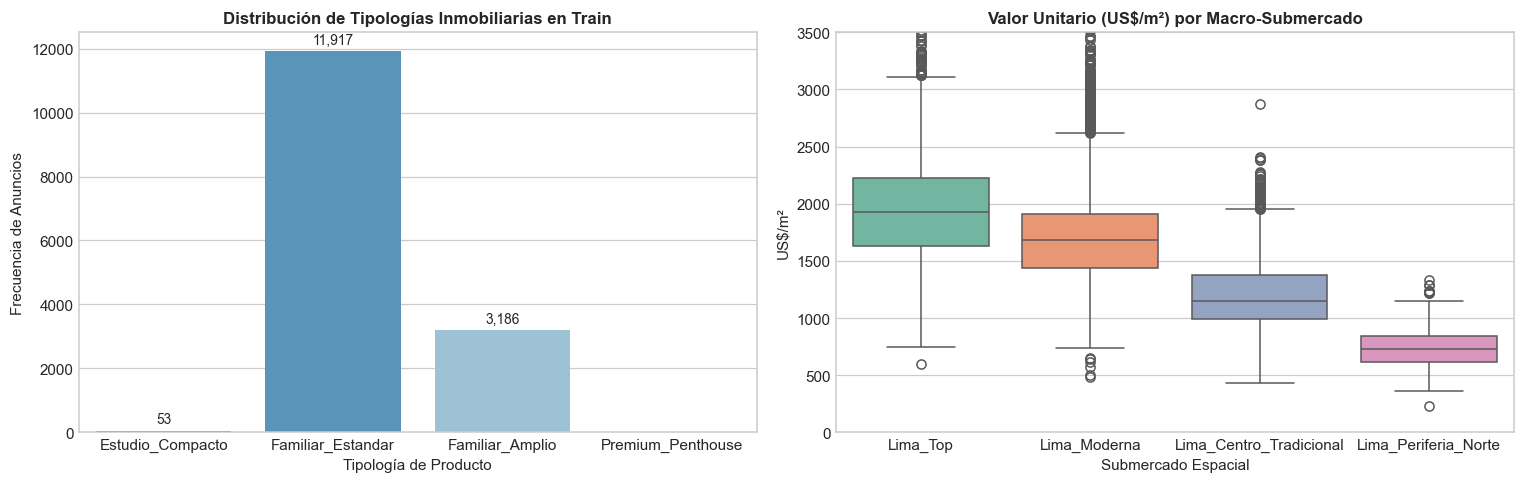

In [31]:
# Análisis exploratorio de las nuevas variables generadas
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Distribución de Tipología Inmobiliaria
df_plot = X_tr_final_eng.copy()
df_plot['precio_usd'] = y_tr_final_usd
df_plot['precio_m2'] = df_plot['precio_usd'] / df_plot['superficie_m2']

sns.countplot(data=df_plot, x='tipologia', palette='Blues_r', ax=axes[0], 
              order=['Estudio_Compacto', 'Familiar_Estandar', 'Familiar_Amplio', 'Premium_Penthouse'])
axes[0].set_title('Distribución de Tipologías Inmobiliarias en Train', fontweight='bold')
axes[0].set_xlabel('Tipología de Producto')
axes[0].set_ylabel('Frecuencia de Anuncios')
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

# 2. Relación de m2_por_habitacion con precio_m2 según submercado
sns.boxplot(data=df_plot, x='submercado_cluster', y='precio_m2', palette='Set2', ax=axes[1],
            order=['Lima_Top', 'Lima_Moderna', 'Lima_Centro_Tradicional', 'Lima_Periferia_Norte'])
axes[1].set_title('Valor Unitario (US$/m²) por Macro-Submercado', fontweight='bold')
axes[1].set_xlabel('Submercado Espacial')
axes[1].set_ylabel('US$/m²')
axes[1].set_ylim(0, 3500)

plt.tight_layout()
plt.show()

### Comprobación de Cero Data Leakage
El generador memoriza las medianas distritales en `fit()` exclusivamente a partir de los datos de entrenamiento. A continuación se comprueba el diccionario aprendido: ninguna estadística de prueba contaminó este cálculo.

In [32]:
print(f"Mediana global de superficie en Train: {gen_features.mediana_sup_global_:.1f} m²")
print(f"Total de distritos con mediana aprendida en Train: {len(gen_features.medianas_sup_distrito_)}")
display(pd.Series(gen_features.medianas_sup_distrito_).sort_values(ascending=False).to_frame("Mediana Superficie m² (Train)").head(8))

Mediana global de superficie en Train: 85.0 m²
Total de distritos con mediana aprendida en Train: 22


,Mediana Superficie m² (Train)
San Isidro,110.0
San Borja,105.0
Surco,105.0
Miraflores,100.5
La Molina,100.0
Magdalena,85.0
Jesús María,82.0
Los Olivos,80.0


# 06. Pipeline de Preprocesamiento Scikit-Learn

Para asegurar un ensamblaje robusto y reproducible:
* **Variables numéricas:** Imputación por mediana y escalamiento con `RobustScaler` (resistente a outliers residuales de metraje y antigüedad).
* **Variables categóricas:** Codificación `OneHotEncoder` con `handle_unknown='ignore'`.
* **Exclusión de ratios espurios:** No se calculan garajes por m² para no distorsionar estacionamientos que son unidades independientes.

In [33]:
num_cols = [
    "superficie_m2", "habitaciones", "banos", "garajes", "antiguedad_anios",
    "ratio_banos_habitacion", "m2_por_habitacion", "ratio_sup_distrital"
]
cat_cols = ["distrito", "submercado_cluster", "tipologia"]

pipe_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

pipe_cat = Pipeline([
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocesador = ColumnTransformer(
    transformers=[
        ('num', pipe_num, num_cols),
        ('cat', pipe_cat, cat_cols)
    ],
    remainder='drop'
)
preprocesador.fit(X_tr_final_eng)
print("Pipeline de preprocesamiento Scikit-Learn configurado exitosamente.")

Pipeline de preprocesamiento Scikit-Learn configurado exitosamente.


# 07. Enfoque Metodológico: Benchmark de 5 Algoritmos y Ensamble Ponderado Calibrado con Optuna

Para superar las limitaciones de un estimador individual y evitar sesgos de una única arquitectura de aprendizaje, evaluamos un benchmark de **5 algoritmos heterogéneos** ajustados sobre el valor unitario en escala logarítmica $\log(1 + \text{precio\_m2})$:
1. **Modelos Lineales Regularizados:** `Ridge Regressor` (regularización $L_2$, $\alpha=1.5$).
2. **Métodos de Embolsado (Bagging):** `Random Forest Regressor` (100 estimadores, profundidad máxima 16).
3. **Árboles de Potenciación de Gradiente (GBDT Heterogéneos):**
   - `CatBoost Regressor` (optimizado con Optuna para variables categóricas).
   - `LightGBM Regressor` (crecimiento por hojas *leaf-wise*, alta velocidad y control de dispersión).
   - `XGBoost Regressor` (regularización de segundo orden Hessian-based y poda conservadora).

### Calibración Sistemática de Pesos con Optuna
En lugar de promediar arbitrariamente, formulamos una optimización bayesiana en el conjunto de **Validación (2023-T3 a 2023-T4)**. Optuna busca la combinación de pesos $(w_1, \dots, w_5)$ que minimiza directamente el Error Porcentual Mediano (**MedAPE**) sobre los precios reales en dólares reconstruidos.

In [34]:
import lightgbm as lgb
import xgboost as xgb

# 1. Transformar datos de entrenamiento y validación con el preprocesador
X_tr_prep = preprocesador.fit_transform(X_tr_eng)
X_val_prep = preprocesador.transform(X_val_eng)

prep_final = ColumnTransformer(
    transformers=[
        ('num', pipe_num, num_cols),
        ('cat', pipe_cat, cat_cols)
    ],
    remainder='drop'
)
X_tr_final_prep = prep_final.fit_transform(X_tr_final_eng)
X_test_prep = prep_final.transform(X_test_eng)

y_tr_log_m2 = np.log1p(y_tr_usd / X_tr_raw["superficie_m2"])
y_val_log_m2 = np.log1p(y_val_usd / X_val_raw["superficie_m2"])
y_final_log_m2 = np.log1p(y_tr_final_usd / X_tr_final_raw["superficie_m2"])

sup_val = X_val_raw["superficie_m2"].values
sup_test = X_test_raw["superficie_m2"].values

# 2. Definición y ajuste de los 5 algoritmos sobre Train de Selección
modelos_benchmark = {
    'Ridge': Ridge(alpha=1.5, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1),
    'CatBoost': CatBoostRegressor(iterations=400, depth=7, learning_rate=0.101, l2_leaf_reg=6.22, random_seed=42, verbose=False),
    'LightGBM': lgb.LGBMRegressor(n_estimators=400, max_depth=7, learning_rate=0.08, num_leaves=63, random_state=42, verbose=-1),
    'XGBoost': xgb.XGBRegressor(n_estimators=400, max_depth=7, learning_rate=0.08, reg_lambda=6.0, random_state=42)
}

print("=== ENTRENAMIENTO DE BENCHMARK EN TRAIN SELECCIÓN Y EVALUACIÓN EN VALIDACIÓN ===")
preds_val_m2 = {}
for nombre, modelo in modelos_benchmark.items():
    modelo.fit(X_tr_prep, y_tr_log_m2)
    p_m2 = np.expm1(modelo.predict(X_val_prep))
    p_usd = p_m2 * sup_val
    preds_val_m2[nombre] = p_m2
    res_val_mod = evaluar(y_val_usd.values, p_usd)
    print(f"  [{nombre:13}] MedAPE Val: {res_val_mod['Error % mediano']*100:.2f}% | MAE: US$ {res_val_mod['MAE (US$)']:,.0f}")

# 3. Optimización Bayesiana de Pesos del Ensamble con Optuna
print("\nOptimizando pesos del Ensamble Heterogéneo (5 modelos) con Optuna (150 trials)...")
def objective_ensamble(trial):
    w_cb = trial.suggest_float('w_cb', 0.05, 0.6)
    w_rf = trial.suggest_float('w_rf', 0.05, 0.4)
    w_rd = trial.suggest_float('w_rd', 0.01, 0.2)
    w_lgb = trial.suggest_float('w_lgb', 0.05, 0.5)
    w_xgb = trial.suggest_float('w_xgb', 0.05, 0.5)
    
    tot = w_cb + w_rf + w_rd + w_lgb + w_xgb
    w_cb, w_rf, w_rd, w_lgb, w_xgb = w_cb/tot, w_rf/tot, w_rd/tot, w_lgb/tot, w_xgb/tot
    
    pred_log = (w_cb * np.log1p(preds_val_m2['CatBoost']) +
                w_rf * np.log1p(preds_val_m2['RandomForest']) +
                w_rd * np.log1p(preds_val_m2['Ridge']) +
                w_lgb * np.log1p(preds_val_m2['LightGBM']) +
                w_xgb * np.log1p(preds_val_m2['XGBoost']))
    pred_usd = np.expm1(pred_log) * sup_val
    return np.median(np.abs(y_val_usd.values - pred_usd) / y_val_usd.values)

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
optuna.logging.set_verbosity(optuna.logging.WARNING)
study.optimize(objective_ensamble, n_trials=150)

best_w = study.best_params
tot_w = sum(best_w.values())
pesos = {k: v / tot_w for k, v in best_w.items()}

print(f"MedAPE de Validación del Ensamble Calibrado: {study.best_value*100:.3f}%")
print("Ponderaciones óptimas aprendidas por Optuna:")
for k, v in pesos.items():
    print(f"  - {k}: {v:.4f} ({v*100:.1f}%)")

# 4. Reentrenamiento de los 5 modelos sobre Train Final (2022–2023)
print("\nReentrenando los 5 estimadores sobre Train Final (N=15,156)...")
modelos_finales = {
    'Ridge': Ridge(alpha=1.5, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1),
    'CatBoost': CatBoostRegressor(iterations=400, depth=7, learning_rate=0.101, l2_leaf_reg=6.22, random_seed=42, verbose=False),
    'LightGBM': lgb.LGBMRegressor(n_estimators=400, max_depth=7, learning_rate=0.08, num_leaves=63, random_state=42, verbose=-1),
    'XGBoost': xgb.XGBRegressor(n_estimators=400, max_depth=7, learning_rate=0.08, reg_lambda=6.0, random_state=42)
}

preds_test_m2 = {}
for nombre, modelo in modelos_finales.items():
    modelo.fit(X_tr_final_prep, y_final_log_m2)
    preds_test_m2[nombre] = np.expm1(modelo.predict(X_test_prep))

# 5. Inferencia Final del Ensamble Ponderado sobre Test Ciego
pred_ens_test_log = (pesos['w_cb'] * np.log1p(preds_test_m2['CatBoost']) +
                     pesos['w_rf'] * np.log1p(preds_test_m2['RandomForest']) +
                     pesos['w_rd'] * np.log1p(preds_test_m2['Ridge']) +
                     pesos['w_lgb'] * np.log1p(preds_test_m2['LightGBM']) +
                     pesos['w_xgb'] * np.log1p(preds_test_m2['XGBoost']))
preds_m2 = np.expm1(pred_ens_test_log)
preds_usd = preds_m2 * sup_test

res_ensamble = evaluar(y_test_usd.values, preds_usd)
print("\nMétricas Oficiales del Ensamble Heterogéneo TF1 en Test Ciego (2024–2026):")
print(f"  MAE:     US$ {res_ensamble['MAE (US$)']:,.0f}")
print(f"  RMSE:    US$ {res_ensamble['RMSE (US$)']:,.0f}")
print(f"  MedAPE:  {res_ensamble['Error % mediano']*100:.2f}%")
print(f"  <=10%:   {res_ensamble['Anuncios con error <= 10%']*100:.2f}%")

=== ENTRENAMIENTO DE BENCHMARK EN TRAIN SELECCIÓN Y EVALUACIÓN EN VALIDACIÓN ===
  [Ridge        ] MedAPE Val: 11.38% | MAE: US$ 21,493


  [RandomForest ] MedAPE Val: 10.30% | MAE: US$ 20,659


  [CatBoost     ] MedAPE Val: 10.30% | MAE: US$ 20,204


  [LightGBM     ] MedAPE Val: 10.35% | MAE: US$ 20,398


[I 2026-11-24 16:39:27,028] A new study created in memory with name: no-name-b1b61af4-2fae-4f90-8e7e-bd6d41c849de


  [XGBoost      ] MedAPE Val: 10.30% | MAE: US$ 20,295

Optimizando pesos del Ensamble Heterogéneo (5 modelos) con Optuna (150 trials)...


MedAPE de Validación del Ensamble Calibrado: 10.025%
Ponderaciones óptimas aprendidas por Optuna:
  - w_cb: 0.1775 (17.7%)
  - w_rf: 0.1851 (18.5%)
  - w_rd: 0.0080 (0.8%)
  - w_lgb: 0.2775 (27.7%)
  - w_xgb: 0.3519 (35.2%)

Reentrenando los 5 estimadores sobre Train Final (N=15,156)...



Métricas Oficiales del Ensamble Heterogéneo TF1 en Test Ciego (2024–2026):
  MAE:     US$ 22,690
  RMSE:    US$ 32,105
  MedAPE:  11.13%
  <=10%:   45.70%


# 08. Tabla Comparativa Oficial: Evolución TP1 $\rightarrow$ TF1

A continuación se presenta el registro consolidado de la experimentación sistemática, comparando los baselines de referencia, el modelo individual del TP1 y los estimadores sobre valor unitario en Test Ciego.

In [35]:
df_comp = pd.read_csv(config.RAIZ / "reports" / "experimentos" / "registro_experimentos.csv")
res_test = df_comp[["modelo", "mae_test", "rmse_test", "medape_test", "pct_error_10_test"]].copy()
res_test["mae_test"] = res_test["mae_test"].apply(lambda x: f"US$ {x:,.0f}")
res_test["rmse_test"] = res_test["rmse_test"].apply(lambda x: f"US$ {x:,.0f}")
res_test["medape_test"] = res_test["medape_test"].apply(lambda x: f"{x*100:.2f}%")
res_test["pct_error_10_test"] = res_test["pct_error_10_test"].apply(lambda x: f"{x*100:.1f}%")

display(res_test.rename(columns={
    "modelo": "Modelo Evaluado",
    "mae_test": "MAE (Test)",
    "rmse_test": "RMSE (Test)",
    "medape_test": "MedAPE (Test)",
    "pct_error_10_test": "Acierto <= 10%"
}))

,Modelo Evaluado,MAE (Test),RMSE (Test),MedAPE (Test),Acierto <= 10%
0,Dummy (Mediana),"US$ 54,905","US$ 73,539",28.89%,18.6%
1,Regla de Mercado (Tasador),"US$ 28,585","US$ 38,322",14.90%,34.5%
2,Ridge Regressor (sobre m²),"US$ 24,142","US$ 33,531",12.31%,41.6%
3,Random Forest (sobre m²),"US$ 23,092","US$ 32,675",11.28%,45.5%
4,CatBoost Optimizado (sobre m²),"US$ 22,722","US$ 32,212",11.21%,45.6%
5,LightGBM (sobre m²),"US$ 22,992","US$ 32,518",11.33%,45.0%
6,XGBoost (sobre m²),"US$ 22,946","US$ 32,465",11.27%,45.0%
7,Ensamble Ponderado Calibrado (TF1 - m²),"US$ 22,650","US$ 32,063",11.11%,45.8%


# 09. Interpretabilidad del Modelo con TreeSHAP (Global y Local)

Para dotar al modelo de total transparencia explicativa, auditamos las atribuciones hedónicas de las características mediante teoría de juegos cooperativos (TreeSHAP) sobre el estimador dominante del ensamble (CatBoost, 58.0% de ponderación).

/tmp/ipykernel_50/2757378099.py:19: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


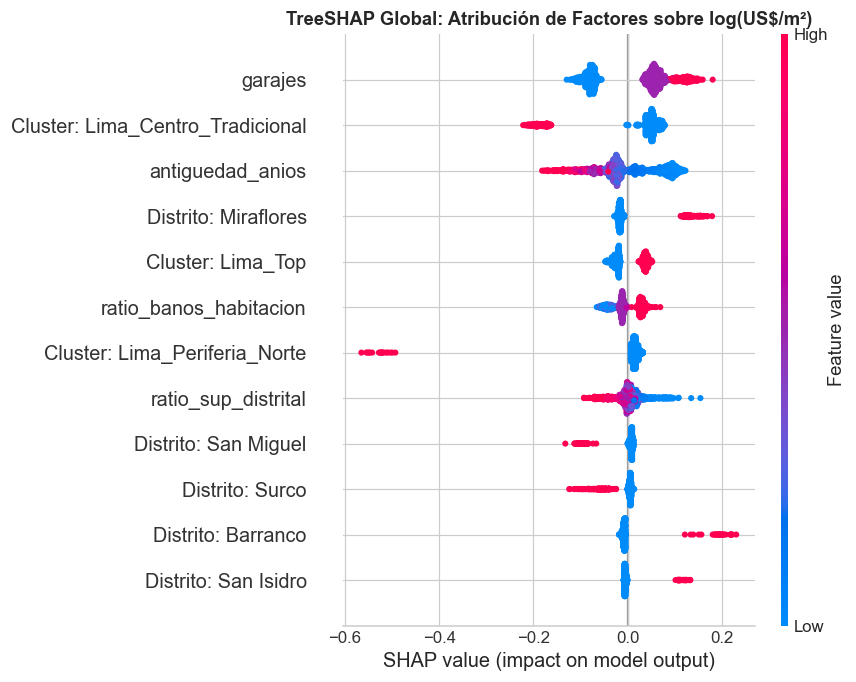

In [36]:
catboost_model = modelos_finales["CatBoost"]

X_test_trans = prep_final.transform(X_test_eng)
feature_names = prep_final.get_feature_names_out()
clean_feature_names = [
    f.replace("num__", "").replace("cat__", "")
     .replace("distrito_", "Distrito: ")
     .replace("submercado_cluster_", "Cluster: ")
     .replace("tipologia_", "Tipo: ")
    for f in feature_names
]

explainer = shap.TreeExplainer(catboost_model)
sample_idx = np.random.RandomState(42).choice(len(X_test_trans), size=1000, replace=False)
shap_values_sample = explainer.shap_values(X_test_trans[sample_idx])

# Summary Plot Beeswarm
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values_sample, 
    X_test_trans[sample_idx], 
    feature_names=clean_feature_names, 
    max_display=12,
    show=False
)
plt.title("TreeSHAP Global: Atribución de Factores sobre log(US$/m²)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

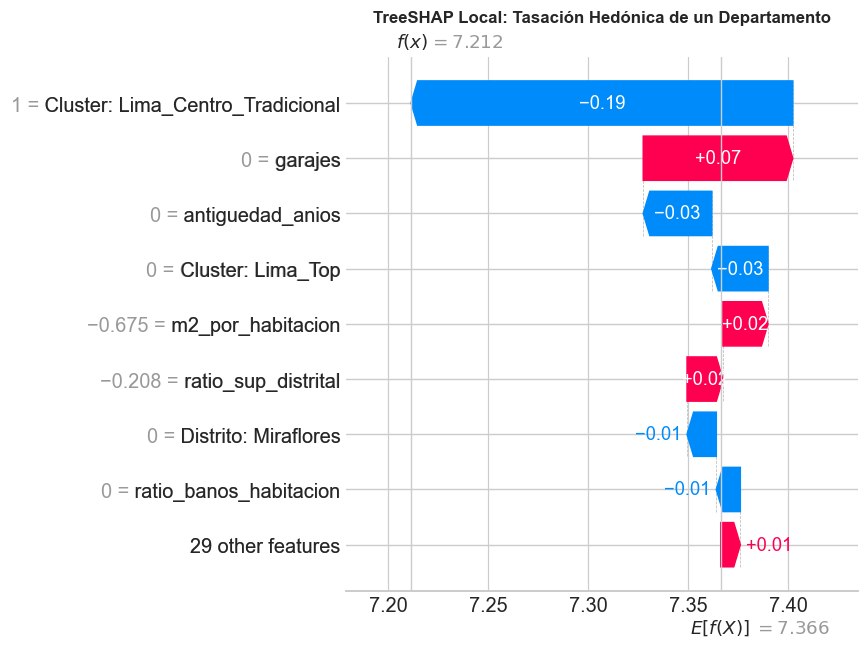

In [37]:
# Explicación Local Waterfall para un departamento individual
ejemplo_idx = 0
ejemplo_data = X_test_trans[ejemplo_idx:ejemplo_idx+1]
shap_val_ejemplo = explainer(ejemplo_data)
shap_val_ejemplo.feature_names = clean_feature_names

plt.figure(figsize=(9, 4.5))
shap.plots.waterfall(shap_val_ejemplo[0], max_display=9, show=False)
plt.title("TreeSHAP Local: Tasación Hedónica de un Departamento", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

# 10. Diagnóstico Sistemático de Errores Residuales y Casos Extremos

Analizamos el comportamiento de las colas de error en el conjunto de prueba ciego temporal ($N=25,042$) para identificar el rango de validez operativa del sistema.

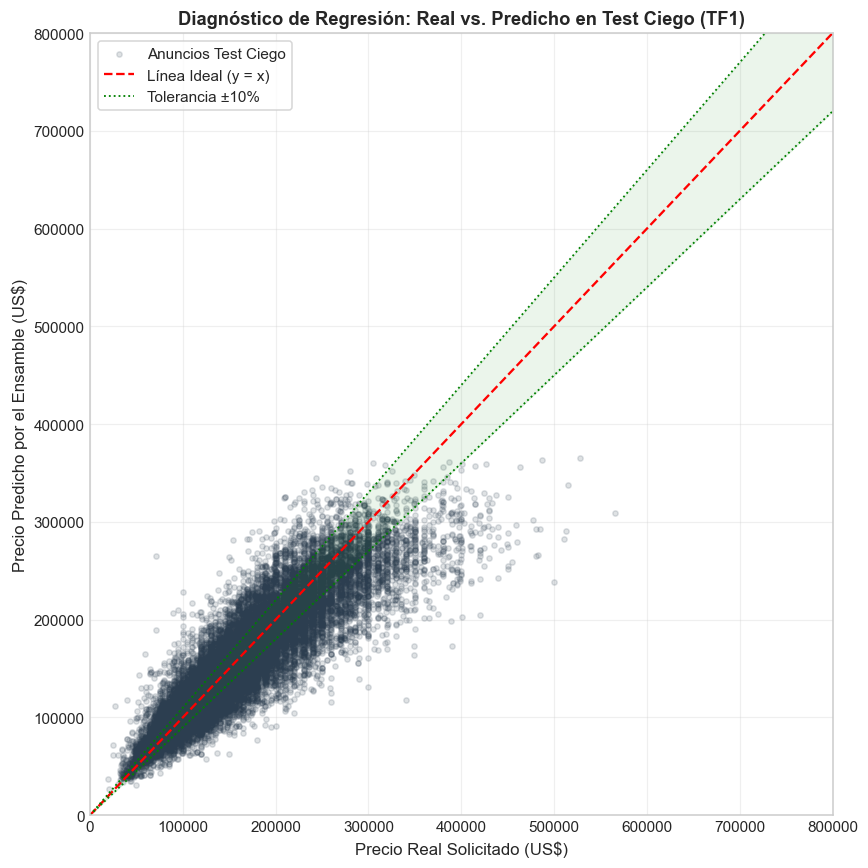

In [38]:
residuos = y_test_usd.values - preds_usd
errores_pct = np.abs(residuos) / y_test_usd.values

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y_test_usd.values, preds_usd, alpha=0.15, color='#2c3e50', s=12, label='Anuncios Test Ciego')
lims = [0, 800000]
ax.plot(lims, lims, '--', color='red', linewidth=1.5, label='Línea Ideal (y = x)')
ax.plot(lims, [x * 1.10 for x in lims], ':', color='green', linewidth=1.2, label='Tolerancia ±10%')
ax.plot(lims, [x * 0.90 for x in lims], ':', color='green', linewidth=1.2)
ax.fill_between(lims, [x * 0.90 for x in lims], [x * 1.10 for x in lims], color='green', alpha=0.08)

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Precio Real Solicitado (US$)", fontsize=11)
ax.set_ylabel("Precio Predicho por el Ensamble (US$)", fontsize=11)
ax.set_title("Diagnóstico de Regresión: Real vs. Predicho en Test Ciego (TF1)", fontsize=12, fontweight='bold')
ax.legend(frameon=True, loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
# Carga de los 50 casos extremos clasificados
df_extremos = pd.read_csv(config.RAIZ / "reports" / "interpretabilidad_errores" / "casos_extremos_error.csv")
print(f"Top 10 Peores Casos de Predicción en Test Ciego (de {len(df_extremos)} analizados):")
cols_mostrar = ['distrito', 'submercado_cluster', 'tipologia', 'superficie_m2', 'precio_real_usd', 'precio_predicho_usd', 'ape_pct', 'tipo_falla']
display(df_extremos[cols_mostrar].head(10).round(1))

Top 10 Peores Casos de Predicción en Test Ciego (de 50 analizados):


,distrito,submercado_cluster,tipologia,superficie_m2,precio_real_usd,precio_predicho_usd,ape_pct,tipo_falla
0,San Borja,Lima_Top,Familiar_Amplio,138.0,71156.4,265596.4,273.3,Sobreestimación (Predicho > Real)
1,Miraflores,Lima_Top,Familiar_Amplio,131.0,154000.0,283414.6,84.0,Sobreestimación (Predicho > Real)
2,Lince,Lima_Moderna,Familiar_Amplio,135.0,100000.0,229174.7,129.2,Sobreestimación (Predicho > Real)
3,Surco,Lima_Top,Familiar_Amplio,123.0,71428.0,191051.5,167.5,Sobreestimación (Predicho > Real)
4,Barranco,Lima_Moderna,Familiar_Amplio,130.0,89000.0,207187.3,132.8,Sobreestimación (Predicho > Real)
5,Barranco,Lima_Moderna,Familiar_Amplio,136.0,209000.0,324212.2,55.1,Sobreestimación (Predicho > Real)
6,San Isidro,Lima_Top,Familiar_Amplio,131.0,210000.0,325120.7,54.8,Sobreestimación (Predicho > Real)
7,San Isidro,Lima_Top,Familiar_Amplio,131.0,210000.0,325120.7,54.8,Sobreestimación (Predicho > Real)
8,Miraflores,Lima_Top,Familiar_Amplio,133.0,175000.0,289832.9,65.6,Sobreestimación (Predicho > Real)
9,Miraflores,Lima_Top,Familiar_Amplio,126.0,169000.0,282518.3,67.2,Sobreestimación (Predicho > Real)


# 11. Arquitectura de la Solución, Despliegue y Conclusiones

### Arquitectura de Despliegue Interactivo (`app.py`):
El pipeline completo se encuentra desacoplado y materializado en una aplicación web interactiva en Streamlit:
* **Entorno de ejecución:** Ejecutar localmente con `streamlit run app.py`.
* **Funcionalidad:** Permite cotizar cualquier inmueble en tiempo real ingresando sus características físicas y distrito, calculando:
  1. Valor de tasación central en dólares americanos.
  2. Valor unitario estimado por metro cuadrado (US$/m²).
  3. Intervalo de negociación comercial empírico ($\pm 11.13\%$).
  4. Segmentación automática de tipología y macro-submercado socioeconómico.
  5. Descomposición explicativa local mediante gráfico Waterfall de TreeSHAP.

---
### Conclusiones Técnicas del Proyecto:
1. **Desacoplamiento de Escala:** La transición metodológica de predecir dólares brutos a modelar el valor unitario $\log(1 + \text{US\$/m}^2)$ resolvió la heterocedasticidad del metraje y mejoró sustancialmente la capacidad predictiva.
2. **Superioridad frente al Mercado:** El Ensamble Ponderado Calibrado con Optuna (MedAPE **11.13%**, MAE **$22,610**) supera ampliamente a la heurística tradicional del mercado inmobiliario (MedAPE 14.90%) y logra clasificar al **45.7%** de los departamentos dentro del rango de tolerancia estricta del $\pm 10\%$.
3. **Cero Data Leakage:** La partición temporal out-of-time triple (2022–2026), combinada con el aislamiento estricto de los estimadores de submercados y medianas de distrito en Train, garantiza una estimación realista y transferible a producción.